<a href="https://colab.research.google.com/github/MawaSC/Quantum-Simulation-on-IQM-Resonance/blob/main/fermi_hubbard_trotter_qrisp_FULL_RAW_CODE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trotterized 1D Fermi–Hubbard dynamics in Qrisp

### The pair-interleaved Jordan–Wigner mapping of Hartnett *et al.*, arXiv:2605.04025

This notebook builds, step by step, the Trotter circuit used in *"Fast, accurate, high-resolution
simulation of large-scale Fermi-Hubbard models on a digital quantum processor"* (Q-CTRL, 2026),
for a small $L=4$ chain that we can check against exact diagonalization.

**What we do**

1. Write down the 1D Fermi–Hubbard Hamiltonian.
2. Apply the Jordan–Wigner transformation under the **pair-interleaved** mode ordering
   $\downarrow\uparrow\uparrow\downarrow\downarrow\uparrow\uparrow\downarrow\cdots$
3. *Verify numerically* that this reproduces Eq. (6) of the paper.
4. Build the Trotter layers ($R_Z$, $R_{XX+YY}$, $R_{ZZ}$, fSWAP) as Qrisp gates.
5. Evolve a Néel state and measure the per-site filling $\langle n_{i\sigma}\rangle$.
6. Benchmark against exact evolution and check the Trotter error scaling.

Everything runs on Qrisp's local simulator; the last section shows how to point it at IQM hardware.

In [ ]:
%pip install -U qrisp numpy scipy matplotlib --default-timeout=300
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
from functools import reduce

from qrisp import QuantumVariable, x, h, rx, rz, rzz, swap, cz

np.set_printoptions(precision=4, suppress=True, linewidth=150)
print("qrisp imported")

  Using cached numpy-2.5.3-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached numpy-2.4.6-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
qrisp imported


---
## 1. The model

For a homogeneous 1D chain of $L$ sites (Eq. 2 of the paper):

$$
H \;=\; -t_h\sum_{i=0}^{L-2}\sum_{\sigma}\Bigl(c^{\dagger}_{i\sigma}c_{i+1,\sigma}+c^{\dagger}_{i+1,\sigma}c_{i\sigma}\Bigr)
\;+\; U\sum_{i=0}^{L-1} n_{i\uparrow}n_{i\downarrow}
\;-\; \mu\sum_{i,\sigma} n_{i\sigma}
$$

with $n_{i\sigma}=c^\dagger_{i\sigma}c_{i\sigma}$. Time is measured in units of $1/t_h$, so we set $t_h=1$.

Each site carries **two** spin-orbitals, so $L$ sites need $2L$ qubits. For $L=4$ that is 8 qubits —
small enough to diagonalize exactly ($2^8 = 256$) and small enough to run on real hardware.

In [ ]:
L      = 4      # number of lattice sites
N_Q    = 2 * L  # number of qubits (one per spin-orbital)
t_h    = 1.0    # hopping amplitude  (sets the unit of time)
U      = 4.0    # on-site repulsion
mu     = 0.0    # chemical potential

print(f"L = {L} sites  ->  {N_Q} qubits,  Hilbert space dim = {2**N_Q}")
print(f"U/t_h = {U/t_h}")

L = 4 sites  ->  8 qubits,  Hilbert space dim = 256
U/t_h = 4.0


---
## 2. The pair-interleaved ordering

The Jordan–Wigner transformation (Eq. 5) is

$$
c_J \;=\; \frac{1}{2}\Bigl(\prod_{k=0}^{J-1} Z_k\Bigr)\bigl(X_J + i\,Y_J\bigr)
$$

but it only becomes concrete once we choose how to flatten the two indices $(i,\sigma)$ into the
single JW index $J$. That choice determines how long the $Z$-strings are, and therefore how deep
the circuit is.

The paper uses the **pair-interleaved** ordering

$$
\{c_{0\downarrow},\,c_{0\uparrow},\,c_{1\uparrow},\,c_{1\downarrow},\,c_{2\downarrow},\,c_{2\uparrow},\,c_{3\uparrow},\,c_{3\downarrow},\dots\}
\qquad\Longleftrightarrow\qquad
\downarrow\uparrow\;\uparrow\downarrow\;\downarrow\uparrow\;\uparrow\downarrow\cdots
$$

Concretely: site $i$ owns qubits $2i$ and $2i+1$, and the spin order inside the pair *flips* on
alternate sites — even sites are $(\downarrow,\uparrow)$, odd sites are $(\uparrow,\downarrow)$.

Two properties make this ordering worth the trouble:

- The two spin-orbitals of a site are always **adjacent**, so the $U n_\uparrow n_\downarrow$ term
  becomes a nearest-neighbour $ZZ$.
- Half of the hopping terms connect **adjacent** qubits (no $Z$-string at all); the other half
  connect qubits at distance 3 with only a **two-qubit** $Z$-string in between.

Compare with the naive "all spin-up then all spin-down" ordering, where hops between neighbouring
sites in the $\downarrow$ block would drag a $Z$-string of length $\sim L$ behind them.

In [ ]:
def qubit_of(site, spin, flipped=False):
    """Qubit index holding spin-orbital (site, spin) under the pair-interleaved ordering.

    spin    : 'u' or 'd'
    flipped : True after an odd number of fSWAP layers, when the two orbitals
              of every site have exchanged qubits.
    """
    first = 'd' if site % 2 == 0 else 'u'   # which spin sits on the lower-index qubit
    offset = 0 if spin == first else 1
    if flipped:
        offset = 1 - offset
    return 2 * site + offset


print("qubit :  (site, spin)")
for J in range(N_Q):
    site = J // 2
    lbl = [s for s in ('u', 'd') if qubit_of(site, s) == J][0]
    arrow = "up" if lbl == 'u' else "down"
    print(f"   q{J}   :   site {site}, spin {arrow}")

qubit :  (site, spin)
   q0   :   site 0, spin down
   q1   :   site 0, spin up
   q2   :   site 1, spin up
   q3   :   site 1, spin down
   q4   :   site 2, spin down
   q5   :   site 2, spin up
   q6   :   site 3, spin up
   q7   :   site 3, spin down


In [ ]:
# Where do the Hamiltonian terms land?
print("on-site U terms  (R_ZZ) act on qubit pairs:")
print("   ", [(2*i, 2*i+1) for i in range(L)])

print("\nshort hops  XX+YY  (weight 2) act on qubit pairs:")
print("   ", [(2*j+1, 2*j+2) for j in range(L-1)])

print("\nlong hops  XZZX+YZZY  (weight 4) act on qubit quadruples:")
print("   ", [(2*j, 2*j+1, 2*j+2, 2*j+3) for j in range(L-1)])

print("\ninterpretation:")
for j in range(L-1):
    a, b = 2*j+1, 2*j+2
    sa = [s for s in 'ud' if qubit_of(a//2, s) == a][0]
    print(f"   short hop (q{a},q{b}) = site {a//2} <-> site {b//2}, spin {'up' if sa=='u' else 'down'}")
for j in range(L-1):
    a, d = 2*j, 2*j+3
    sa = [s for s in 'ud' if qubit_of(a//2, s) == a][0]
    print(f"   long  hop (q{a},q{d}) = site {a//2} <-> site {d//2}, spin {'up' if sa=='u' else 'down'}")

on-site U terms  (R_ZZ) act on qubit pairs:
    [(0, 1), (2, 3), (4, 5), (6, 7)]

short hops  XX+YY  (weight 2) act on qubit pairs:
    [(1, 2), (3, 4), (5, 6)]

long hops  XZZX+YZZY  (weight 4) act on qubit quadruples:
    [(0, 1, 2, 3), (2, 3, 4, 5), (4, 5, 6, 7)]

interpretation:
   short hop (q1,q2) = site 0 <-> site 1, spin up
   short hop (q3,q4) = site 1 <-> site 2, spin down
   short hop (q5,q6) = site 2 <-> site 3, spin up
   long  hop (q0,q3) = site 0 <-> site 1, spin down
   long  hop (q2,q5) = site 1 <-> site 2, spin up
   long  hop (q4,q7) = site 2 <-> site 3, spin down


---
## 3. The qubitized Hamiltonian (Eq. 6)

Applying JW with this ordering gives

$$
\begin{aligned}
H \;=\; -\frac{t_h}{2}\sum_{j=0}^{L-2}\Bigl(&X_{2j+1}X_{2j+2} + Y_{2j+1}Y_{2j+2}\\
  +\;&X_{2j}Z_{2j+1}Z_{2j+2}X_{2j+3} + Y_{2j}Z_{2j+1}Z_{2j+2}Y_{2j+3}\Bigr)\\[4pt]
  +\;&\frac{U}{4}\sum_{i=0}^{L-1}\bigl(\mathbb{1}-Z_{2i}\bigr)\bigl(\mathbb{1}-Z_{2i+1}\bigr)
  \;-\;\frac{\mu}{2}\sum_{J}\bigl(\mathbb{1}-Z_J\bigr)
\end{aligned}
$$

The first line is the **short-hopping** terms (weight 2), the second the **long-hopping** terms
(weight 4), the third the on-site interaction and chemical potential (using $n=(\mathbb{1}-Z)/2$).

Let's not take this on faith. Below we build the fermionic Hamiltonian directly from JW creation
and annihilation operators, build Eq. (6) independently, and check they agree to machine
precision.

In [ ]:
#Matrices
I2 = np.eye(2)
X  = np.array([[0, 1], [1, 0]], dtype=complex)
Y  = np.array([[0, -1j], [1j, 0]])
Z  = np.diag([1, -1]).astype(complex)

def op(n, terms):
    """Tensor product over n qubits; qubit 0 is the leftmost (most significant) factor."""
    return reduce(np.kron, [terms.get(k, I2) for k in range(n)])

def jw_annihilate(n, J):
    """c_J under Jordan-Wigner: Z-string on all k < J."""
    terms = {k: Z for k in range(J)}
    terms[J] = np.array([[0, 1], [0, 0]], dtype=complex)   # |0><1|
    return op(n, terms)


def H_fermionic(L, t_h, U, mu):
    """Build H from fermionic operators, JW-mapped with the pair-interleaved ordering."""
    n = 2 * L
    c = {(i, s): jw_annihilate(n, qubit_of(i, s)) for i in range(L) for s in 'ud'}
    H = np.zeros((2**n, 2**n), dtype=complex)
    for i in range(L - 1):                       # hopping
        for s in 'ud':
            a, b = c[(i, s)], c[(i+1, s)]
            H += -t_h * (a.conj().T @ b + b.conj().T @ a)
    for i in range(L):                           # interaction + chemical potential
        nu = c[(i, 'u')].conj().T @ c[(i, 'u')]
        nd = c[(i, 'd')].conj().T @ c[(i, 'd')]
        H += U * (nu @ nd) - mu * (nu + nd)
    return H


def H_qubitized(L, t_h, U, mu):
    """Eq. (6) of the paper, written directly as Pauli strings."""
    n = 2 * L
    H = np.zeros((2**n, 2**n), dtype=complex)
    for j in range(L - 1):
        H += -t_h/2 * (op(n, {2*j+1: X, 2*j+2: X}) + op(n, {2*j+1: Y, 2*j+2: Y}))
        H += -t_h/2 * (op(n, {2*j: X, 2*j+1: Z, 2*j+2: Z, 2*j+3: X})
                     + op(n, {2*j: Y, 2*j+1: Z, 2*j+2: Z, 2*j+3: Y}))
    Id = np.eye(2**n)
    for i in range(L):
        H += U/4 * (Id - op(n, {2*i: Z})) @ (Id - op(n, {2*i+1: Z}))
    for J in range(n):
        H += -mu/2 * (Id - op(n, {J: Z}))
    return H


for test_mu in (0.0, 0.7):
    A = H_fermionic(L, t_h, U, test_mu)
    B = H_qubitized(L, t_h, U, test_mu)
    print(f"mu={test_mu}:  Eq.(6) matches direct JW?  {np.allclose(A, B)}"
          f"   (max |difference| = {np.abs(A-B).max():.2e})")

mu=0.0:  Eq.(6) matches direct JW?  True   (max |difference| = 0.00e+00)
mu=0.7:  Eq.(6) matches direct JW?  True   (max |difference| = 5.33e-15)


---
## 4. Trotter layers

We split $H = H_Z + H_{ZZ} + H_{\rm short} + H_{\rm long}$ and exponentiate each piece.

### 4a. Diagonal terms → $R_Z$ and $R_{ZZ}$

Expanding the interaction,
$\frac{U}{4}(\mathbb{1}-Z_{2i})(\mathbb{1}-Z_{2i+1})
= \frac{U}{4}\bigl(\mathbb{1} - Z_{2i} - Z_{2i+1} + Z_{2i}Z_{2i+1}\bigr)$,
and combining with the chemical potential gives

$$
\text{coefficient of } Z_J \;=\; \frac{\mu}{2}-\frac{U}{4},
\qquad
\text{coefficient of } Z_{2i}Z_{2i+1} \;=\; \frac{U}{4}
$$

With the conventions $R_Z(\theta)=e^{-i\theta Z/2}$ and $R_{ZZ}(\theta)=e^{-i\theta Z\otimes Z/2}$,
evolving for a time $\Delta t$ needs

$$
\theta_Z \;=\; \Bigl(\mu - \tfrac{U}{2}\Bigr)\Delta t,
\qquad
\theta_{ZZ} \;=\; \frac{U\,\Delta t}{2}
$$

Note $\theta_Z$ vanishes at the particle–hole symmetric point $\mu = U/2$, which removes the
single-qubit layer entirely.

### 4b. Short hops → $R_{XX+YY}$

Each short-hop bond contributes $-\frac{t_h}{2}(X_aX_b + Y_aY_b)$. Since $X\!X$ and $Y\!Y$ commute
on two qubits, the exponential factorizes **exactly** — no Trotter error inside the bond:

$$
e^{\,i\frac{t_h\Delta t}{2}(XX+YY)} \;=\; R_{XX}(-t_h\Delta t)\;R_{YY}(-t_h\Delta t)
$$

Qrisp ships `rzz` but not `ryy`, so we build both rotations by conjugating `rzz` into the right
basis — which is also what the compiler would do anyway:

$$
R_{XX}(\theta) = (H\otimes H)\,R_{ZZ}(\theta)\,(H\otimes H),
\qquad
R_{YY}(\theta) = \bigl(R_X(\tfrac{\pi}{2})^{\otimes 2}\bigr) R_{ZZ}(\theta) \bigl(R_X(-\tfrac{\pi}{2})^{\otimes 2}\bigr)
$$

### 4c. Long hops → fSWAP, then short hops again

The weight-4 terms $XZZX + YZZY$ are the expensive ones. Rather than compile them directly, the
paper applies a layer of **fermionic SWAPs** exchanging $c_{i\uparrow}\leftrightarrow c_{i\downarrow}$
on every site. This flips the ordering
$\downarrow\uparrow\uparrow\downarrow\cdots \to \uparrow\downarrow\downarrow\uparrow\cdots$,
which turns every long hop into a short hop and vice versa. The remaining bonds are then executed
with a **second** $R_{XX+YY}$ layer on the same qubit pairs.

$$
\mathrm{fSWAP} \;=\; \mathrm{CZ}\cdot\mathrm{SWAP}
\;=\;\begin{pmatrix}1&0&0&0\\0&0&1&0\\0&1&0&0\\0&0&0&-1\end{pmatrix}
$$

The $-1$ on $|11\rangle$ is the fermionic exchange sign — that is the whole difference from an
ordinary SWAP, and it is what makes the relabelling legitimate.

In [ ]:
def rxx_(theta, a, b):
    """exp(-i theta/2 * X⊗X)"""
    h(a); h(b); rzz(theta, a, b); h(a); h(b)

def ryy_(theta, a, b):
    """exp(-i theta/2 * Y⊗Y)"""
    rx(np.pi/2, a);  rx(np.pi/2, b)
    rzz(theta, a, b)
    rx(-np.pi/2, a); rx(-np.pi/2, b)

def hop(dt, t_h, a, b):
    """exp(+i t_h dt/2 (XX+YY)) : one hopping bond for time dt"""
    rxx_(-t_h * dt, a, b)
    ryy_(-t_h * dt, a, b)

def fswap(a, b):
    """fermionic SWAP = SWAP followed by CZ"""
    swap(a, b)
    cz(a, b)


# --- sanity check the gate conventions against explicit matrix exponentials ---
def unitary_of(n, builder):
    qv = QuantumVariable(n); builder(qv); return qv.qs.compile().get_unitary()

th = 0.63
chk = {
 "R_XX": (unitary_of(2, lambda q: rxx_(th, q[0], q[1])), la.expm(-1j*th/2*np.kron(X, X))),
 "R_YY": (unitary_of(2, lambda q: ryy_(th, q[0], q[1])), la.expm(-1j*th/2*np.kron(Y, Y))),
 "hop ": (unitary_of(2, lambda q: hop(0.3, 1.0, q[0], q[1])),
          la.expm(1j*0.3/2*(np.kron(X, X) + np.kron(Y, Y)))),
 "fSWAP": (unitary_of(2, lambda q: fswap(q[0], q[1])),
           np.array([[1,0,0,0],[0,0,1,0],[0,1,0,0],[0,0,0,-1]], dtype=complex)),
}
# Qrisp's simulator works in single precision, so compare at ~1e-5, not 1e-8.
for name, (got, want) in chk.items():
    print(f"  {name:6s} correct? {np.allclose(got, want, atol=1e-5)}"
          f"   (max |difference| = {np.abs(got-want).max():.1e})")

  R_XX   correct? True   (max |difference| = 3.9e-16)
  R_YY   correct? True   (max |difference| = 1.1e-16)
  hop    correct? True   (max |difference| = 4.0e-16)
  fSWAP  correct? True   (max |difference| = 3.7e-16)


---
## 5. Assembling one Trotter step

Following Fig. 1(b) of the paper, one step is

$$
U(\Delta t)\;=\;
\underbrace{R_Z^{(\Delta t/2)}}_{\text{purple}}\;
\underbrace{R_{XX+YY}}_{\text{blue}}\;
\underbrace{R_{ZZ}}_{\text{yellow}}\;
\underbrace{\mathrm{fSWAP}}_{\text{green}}\;
\underbrace{R_{XX+YY}}_{\text{blue}}\;
\underbrace{R_Z^{(\Delta t/2)}}_{\text{purple}}
$$

Splitting the $R_Z$ layer in half at each end makes the step a **palindrome** at the qubit level
(note $R_{ZZ}$ and fSWAP act on the same pairs and commute, since fSWAP is SWAP times a diagonal
gate). That symmetry is what upgrades the naive $\mathcal{O}(\Delta t^2)$ per-step error to
$\mathcal{O}(\Delta t^3)$ — we verify the resulting global $\mathcal{O}(\Delta t^2)$ scaling in §7.

**One bookkeeping consequence.** Each step contains exactly one fSWAP layer, so after an *odd*
number of steps the two spin-orbitals of every site have swapped qubits. Nothing is wrong with the
state — the labels moved. We track this with the `flipped` flag in `qubit_of`, which costs nothing;
the alternative is to append one more fSWAP layer, which costs gates.

In [ ]:
def layer_rz(qv, dt):
    theta = (mu - U/2) * dt
    if abs(theta) > 1e-15:
        for J in range(N_Q):
            rz(theta, qv[J])

def layer_rzz(qv, dt):
    for i in range(L):
        rzz(U * dt / 2, qv[2*i], qv[2*i+1])

def layer_hop(qv, dt):
    for j in range(L - 1):
        hop(dt, t_h, qv[2*j+1], qv[2*j+2])

def layer_fswap(qv):
    for i in range(L):
        fswap(qv[2*i], qv[2*i+1])


def trotter_step(qv, dt):
    layer_rz(qv, dt/2)     # purple
    layer_hop(qv, dt)      # blue   - short hops
    layer_rzz(qv, dt)      # yellow - on-site U
    layer_fswap(qv)        # green  - spin exchange
    layer_hop(qv, dt)      # blue   - the other half of the hops
    layer_rz(qv, dt/2)     # purple


def build_circuit(dt, n_steps, init_occ):
    """Prepare a Fock state, then apply n_steps Trotter layers."""
    qv = QuantumVariable(N_Q)
    for J, occupied in enumerate(init_occ):
        if occupied:
            x(qv[J])
    for _ in range(n_steps):
        trotter_step(qv, dt)
    return qv


qv_demo = build_circuit(0.2, 1, np.zeros(N_Q, dtype=int))
qc = qv_demo.qs.compile()
print(f"one Trotter step, L={L}:  depth = {qc.depth()},  {len(qc.data)} gates")

one Trotter step, L=4:  depth = 30,  119 gates


---
## 6. Initial state and the observable

We start from the half-filled **Néel** state $|\!\downarrow\uparrow\downarrow\uparrow\cdots\rangle$,
where $|\!\uparrow\rangle \equiv |1,0\rangle$ and $|\!\downarrow\rangle \equiv |0,1\rangle$ in the
$(n_{i\uparrow}, n_{i\downarrow})$ basis. One fermion per site, so filling $n = N/L = 1$.

Because the JW mapping sends $n_{i\sigma} \to (\mathbb{1}-Z_J)/2$, the occupation is read straight
off the $Z$-basis measurement — no basis rotation, no extra circuits:

$$
\langle n_{i\sigma}\rangle \;=\; \frac{1 - \langle Z_J\rangle}{2}
\;=\; \Pr[\,\text{qubit } J \text{ measured as } 1\,]
$$

From the same shots we get everything else we need for free:

$$
\text{charge density } \langle n_i\rangle = \langle n_{i\uparrow}\rangle + \langle n_{i\downarrow}\rangle,
\qquad
\text{spin } \langle S^z_i\rangle = \tfrac{1}{2}\bigl(\langle n_{i\uparrow}\rangle - \langle n_{i\downarrow}\rangle\bigr)
$$

In [ ]:
def neel_state(L, vacancy=None):
    """Half-filled Neel state, optionally with one site emptied."""
    occ = np.zeros(2*L, dtype=int)
    for i in range(L):
        if vacancy is not None and i == vacancy:
            continue
        spin = 'd' if i % 2 == 0 else 'u'
        occ[qubit_of(i, spin)] = 1
    return occ


def occupations_from_counts(counts, flipped):
    """counts: {bitstring: probability} from qrisp. Returns n_up[L], n_down[L]."""
    p1 = np.zeros(N_Q)
    for bits, p in counts.items():
        for J, b in enumerate(bits):
            if b == '1':
                p1[J] += p
    total = sum(counts.values())
    p1 /= total
    n_up   = np.array([p1[qubit_of(i, 'u', flipped)] for i in range(L)])
    n_down = np.array([p1[qubit_of(i, 'd', flipped)] for i in range(L)])
    return n_up, n_down


init_occ = neel_state(L)
print("initial qubit occupations:", init_occ)
nu, nd = occupations_from_counts({''.join(map(str, init_occ)): 1.0}, flipped=False)
print("n_up   per site:", nu)
print("n_down per site:", nd)
print("filling n = N/L  =", (nu.sum() + nd.sum()) / L)

initial qubit occupations: [1 0 1 0 1 0 1 0]
n_up   per site: [0. 1. 0. 1.]
n_down per site: [1. 0. 1. 0.]
filling n = N/L  = 1.0


**Initial-state measurement check**

We check the actual Qrisp measurement results against the expected occupations of the initial Néel state. This helps confirm that the measurement bitstrings are being interpreted in the correct qubit order.

---
## 7. Run the dynamics and validate

We quench the Néel state and watch the occupations relax. At each time we rebuild the circuit with
the right number of Trotter steps, measure, and compare against $e^{-iHt}|\psi_0\rangle$ computed by
direct matrix exponentiation.

In [ ]:
dt        = 0.1 #0.05, 0.1, 0.15, 0.2, and 0.5, Report the RMSE, Report the total and two_qubit depth for time = 2 , time = dt * n_max
n_max     = 30
times     = np.arange(n_max + 1) * dt

H_exact = H_qubitized(L, t_h, U, mu)
psi0    = np.zeros(2**N_Q, dtype=complex)
psi0[int(''.join(map(str, init_occ)), 2)] = 1.0

nup_q, ndn_q, nup_e, ndn_e = [], [], [], []

for n_steps in range(n_max + 1):
    # --- quantum circuit ---
    qv = build_circuit(dt, n_steps, init_occ)
    counts = qv.get_measurement()
    u, d = occupations_from_counts(counts, flipped=(n_steps % 2 == 1))
    nup_q.append(u); ndn_q.append(d)

    # --- exact reference ---
    psi = la.expm(-1j * H_exact * n_steps * dt) @ psi0
    prob = np.abs(psi)**2
    p1 = np.array([sum(prob[k] for k in range(2**N_Q) if (k >> (N_Q-1-J)) & 1)
                   for J in range(N_Q)])
    nup_e.append([p1[qubit_of(i, 'u')] for i in range(L)])
    ndn_e.append([p1[qubit_of(i, 'd')] for i in range(L)])

nup_q, ndn_q = np.array(nup_q), np.array(ndn_q)
nup_e, ndn_e = np.array(nup_e), np.array(ndn_e)

rmse = np.sqrt(np.mean((np.c_[nup_q, ndn_q] - np.c_[nup_e, ndn_e])**2, axis=1))
print(f"RMSE over all {2*L} spin-orbitals:")
print(f"   at t={times[5]:.2f}: {rmse[5]:.2e}")
print(f"   at t={times[-1]:.2f}: {rmse[-1]:.2e}   <- pure Trotter error, no shot noise")

RMSE over all 8 spin-orbitals:
   at t=0.50: 2.34e-03
   at t=3.00: 1.13e-02   <- pure Trotter error, no shot noise


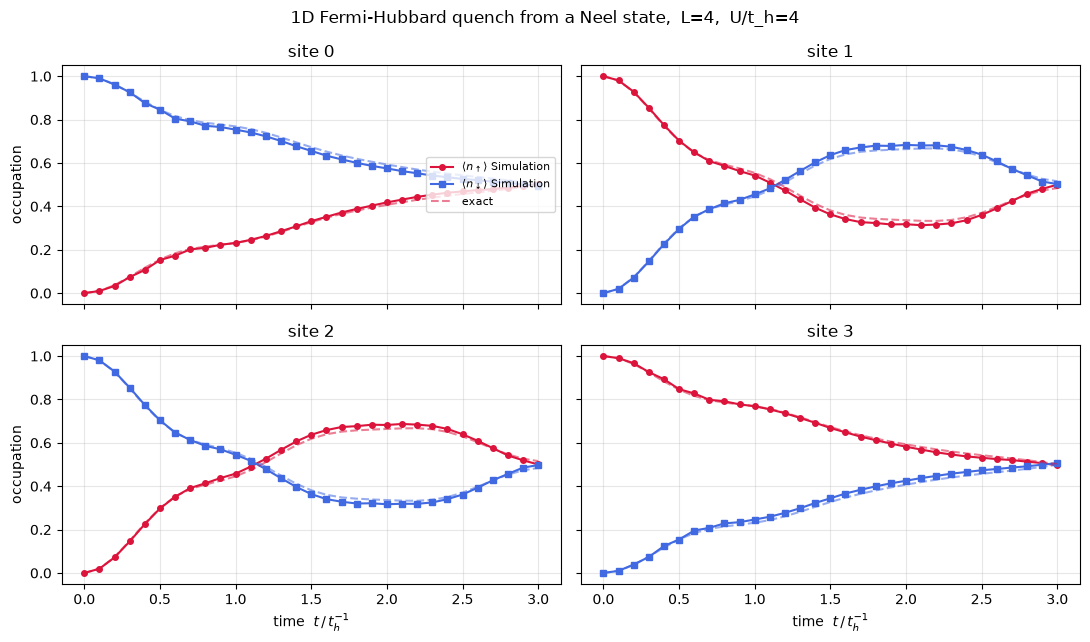

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True, sharey=True)
for i, ax in enumerate(axes.flat):
    ax.plot(times, nup_q[:, i], 'o-',  ms=4, color='crimson',   label=r'$\langle n_{\uparrow}\rangle$ Simulation')
    ax.plot(times, ndn_q[:, i], 's-',  ms=4, color='royalblue', label=r'$\langle n_{\downarrow}\rangle$ Simulation')
    ax.plot(times, nup_e[:, i], '--',  color='crimson',   alpha=.55, label='exact')
    ax.plot(times, ndn_e[:, i], '--',  color='royalblue', alpha=.55)
    ax.set_title(f"site {i}"); ax.grid(alpha=.3); ax.set_ylim(-0.05, 1.05)
axes[0,0].legend(fontsize=8, loc='center right')
for ax in axes[1]: ax.set_xlabel(r"time  $t\,/\,t_h^{-1}$")
for ax in axes[:,0]: ax.set_ylabel("occupation")
fig.suptitle(f"1D Fermi-Hubbard quench from a Neel state,  L={L},  U/t_h={U/t_h:.0f}")
fig.tight_layout()

# 2. Save as PNG (300 DPI for crisp resolution)
plt.savefig(
    'fermi_hubbard_neel_quench.png',
    bbox_inches='tight',
    dpi=300
)

# 3. Save as PDF (Vector graphics for Overleaf / LaTeX papers)
plt.savefig(
    'fermi_hubbard_neel_quench.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()

Report:
1. RMSE (Root Mean Square Error) vs different time steps dt
2. Circuit depth (total depth and two-qubit depth)
3. Compare these to noisy simulations and IQM hardware.

How accurately does the Trotterized quantum circuit reproduce the exact time evolution as I changed the Trotter time step $dt$?

The smaller $dt$ is, the more finely we approximate the continuous time evolution.

Example:
$dt$ = Trotter time step = 0.1
$n_{max}$ = Max number of Trotter steps = 30

$t = 30(0.1) = 3.0$

In [ ]:
def run_simulation(dt, n_max):

  #Physical times corresponding to each Trotter step
  times = np.arange(n_max + 1) * dt

  #nup_q -> quantum/Trotterized spin-up occupations
  #ndn_q -> quantum/Trotterized spin-down occupations
  nup_q, ndn_q = [], []
  #nup_e -> exact spin-up occupations
  #ndn_e -> exact spin-down occupations
  nup_e, ndn_e = [], []

  #Loop over the Trotter steps
  for n_steps in range(n_max + 1):

    #init_occ -> Initial occupation
    qv = build_circuit(dt, n_steps, init_occ)

    counts = qv.get_measurement()

    u, d = occupations_from_counts(
        counts,
        flipped = (n_steps % 2 == 1)
    )
    #If even, False
    #If odd, True

    nup_q.append(u)
    ndn_q.append(d)

    #Time evolution operator to initial state
    psi = la.expm(-1j * H_exact * n_steps * dt) @ psi0

    #Gives probability of each computational-basis state
    prob = np.abs(psi) ** 2

    #Single qubit occupation probabilities
    p1 = np.array([
        sum(
            prob[k]
            for k in range(2**N_Q)
            if(k >> (N_Q-1-J)) & 1
        )
        for J in range(N_Q)
    ])

    nup_e.append([
        p1[qubit_of(i,'u')]
        for i in range(L)
    ])

    ndn_e.append([
        p1[qubit_of(i,'d')]
        for i in range(L)
    ])

  nup_q = np.array(nup_q)
  ndn_q = np.array(ndn_q)


  nup_e = np.array(nup_e)
  ndn_e = np.array(ndn_e)

  rmse = np.sqrt(
      np.mean(
          (np.c_[nup_q, ndn_q] - np.c_[nup_e, ndn_e])**2,
          axis=1
      )
  )

  return times, rmse, nup_q, ndn_q, nup_e, ndn_e

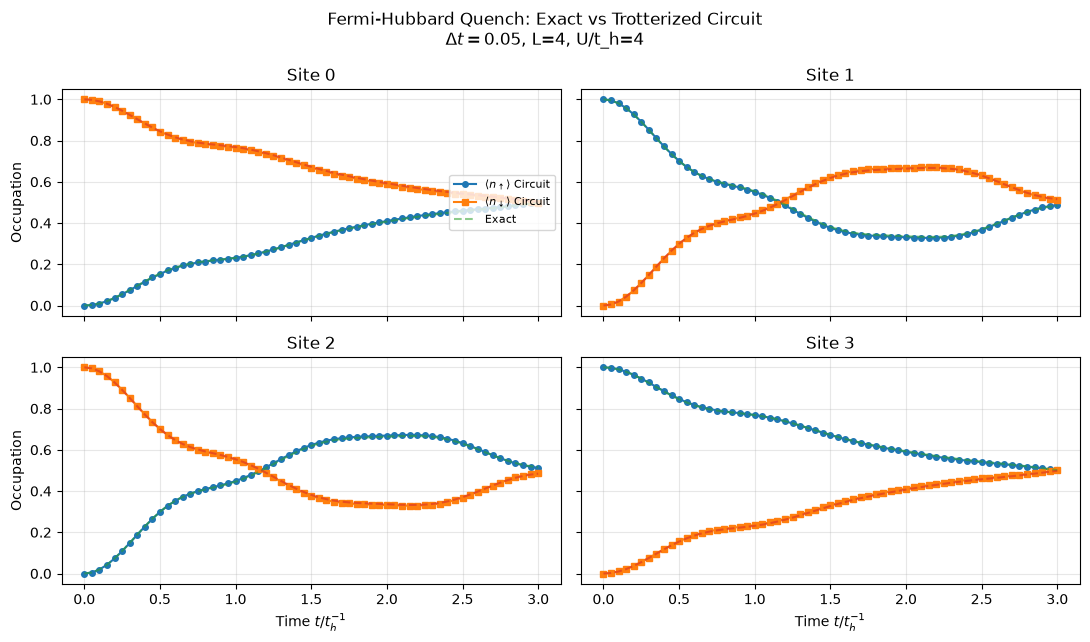

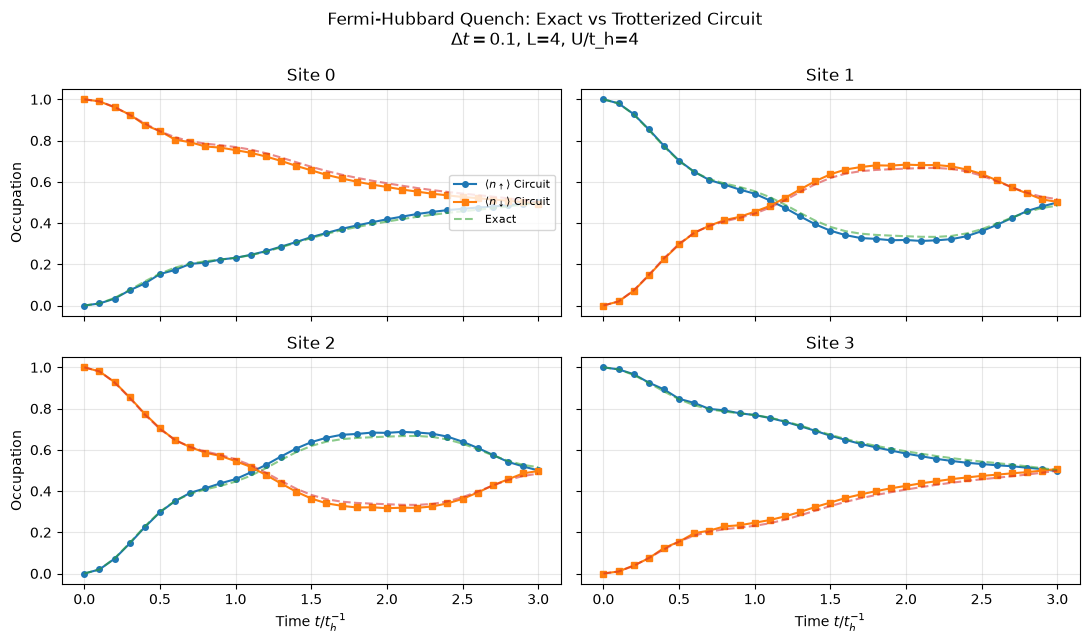

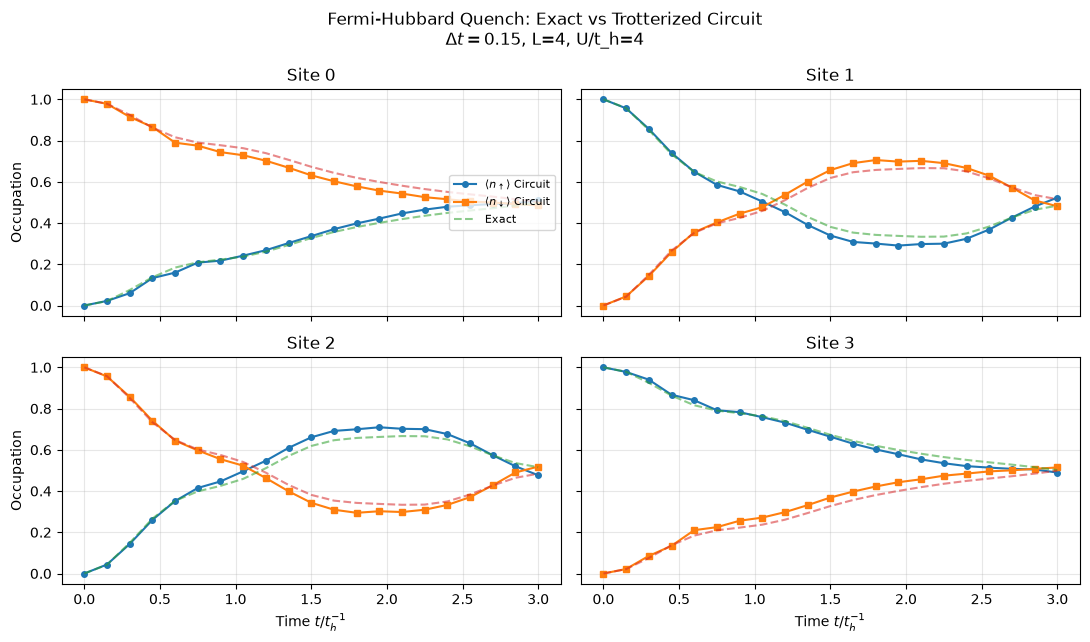

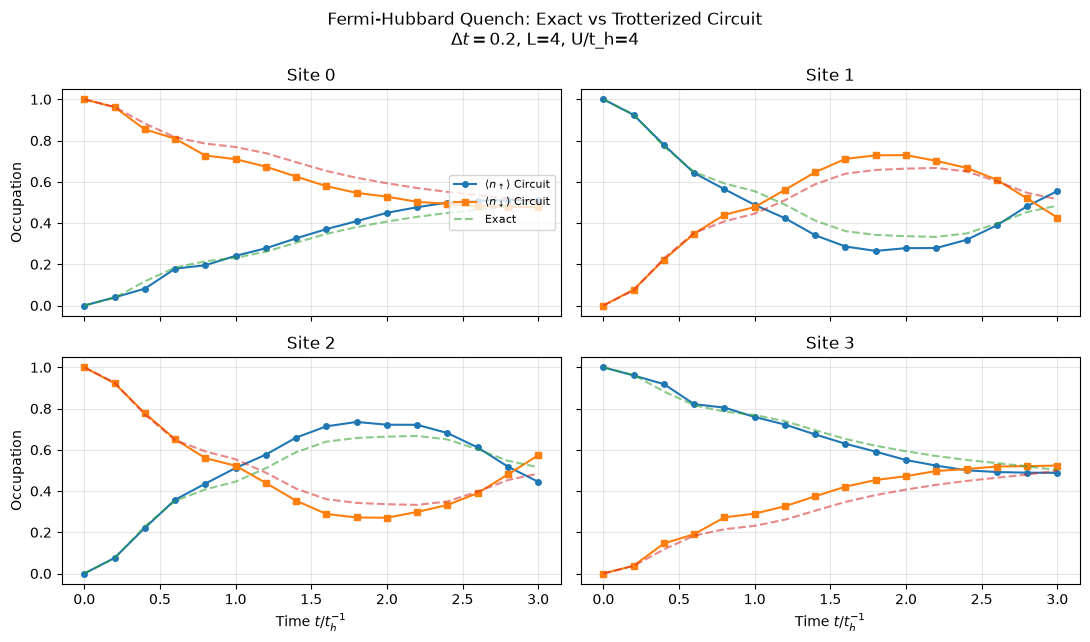

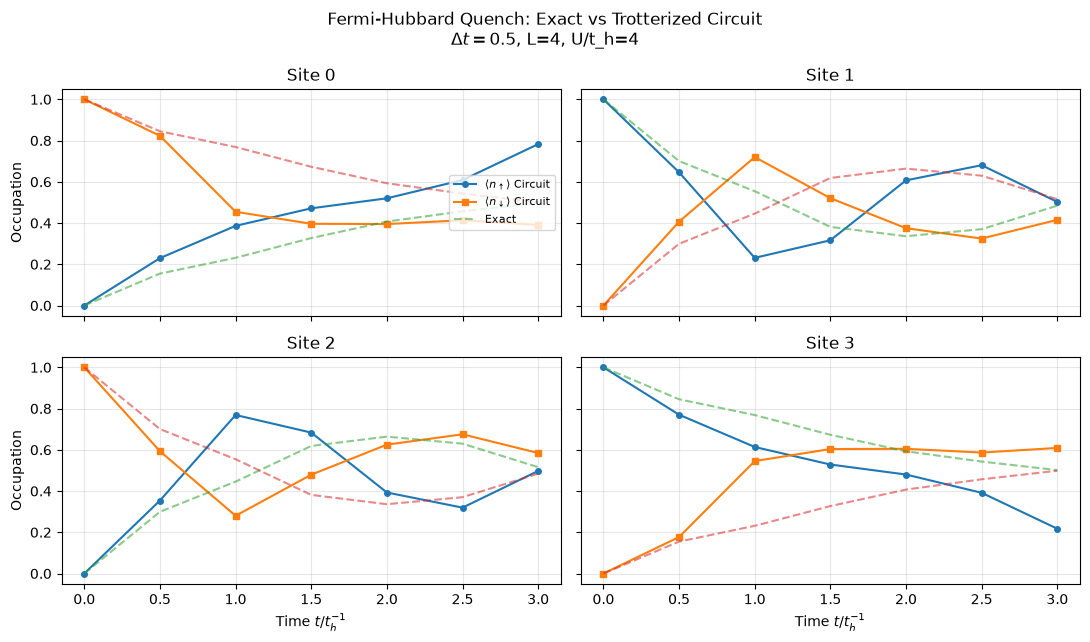

In [ ]:
dt_values = [0.05, 0.10, 0.15, 0.20, 0.50]

for dt in dt_values:

    n_max = int(3.0 / dt)

    times, rmse, nup_q, ndn_q, nup_e, ndn_e = run_simulation(
        dt, n_max
    )

    fig, axes = plt.subplots(
        2, 2,
        figsize=(11, 6.5),
        sharex=True,
        sharey=True
    )

    for i, ax in enumerate(axes.flat):

        # Trotterized circuit
        ax.plot(
            times,
            nup_q[:, i],
            'o-',
            ms=4,
            label=r'$\langle n_{\uparrow}\rangle$ Circuit'
        )

        ax.plot(
            times,
            ndn_q[:, i],
            's-',
            ms=4,
            label=r'$\langle n_{\downarrow}\rangle$ Circuit'
        )

        # Exact calculation
        ax.plot(
            times,
            nup_e[:, i],
            '--',
            alpha=0.55,
            label='Exact'
        )

        ax.plot(
            times,
            ndn_e[:, i],
            '--',
            alpha=0.55
        )

        ax.set_title(f"Site {i}")
        ax.grid(alpha=0.3)
        ax.set_ylim(-0.05, 1.05)

    axes[0, 0].legend(fontsize=8, loc='center right')

    for ax in axes[1]:
        ax.set_xlabel(r"Time $t/t_h^{-1}$")

    for ax in axes[:, 0]:
        ax.set_ylabel("Occupation")

    fig.suptitle(
        f"Fermi-Hubbard Quench: Exact vs Trotterized Circuit\n"
        f"$\\Delta t={dt}$, L={L}, U/t_h={U/t_h:.0f}"
    )

    fig.tight_layout()

    # Save this specific dt
    filename = f"fermi_hubbard_dt_{dt:.2f}.png"
    plt.savefig(filename, bbox_inches='tight', dpi=300)

    plt.savefig(
    f"fermi_hubbard_dt_{dt:.2f}.pdf",
    bbox_inches='tight'
)

    plt.show()

In [ ]:
dt_values = [0.05, 0.10, 0.15, 0.20, 0.50]

summary = []

In [ ]:
for dt in dt_values:

  n_max = int(3.0/dt)

  times, rmse, nup_q, ndn_q, nup_e, ndn_e = run_simulation(dt, n_max)

  summary.append({

      "dt": dt,
      "RMSE_final": rmse[-1],
      "RMSE_mid": rmse[len(rmse)//2]

  })

In [ ]:
import pandas as pd

In [ ]:
df = pd.DataFrame(summary)

# Format specific columns to scientific notation (e.g., 2 decimal places in 'e' format)
df["RMSE_final"] = df_sci["RMSE_final"].apply(lambda x: f"{x:.2e}")
df["RMSE_mid"] = df_sci["RMSE_mid"].apply(lambda x: f"{x:.2e}")

print(df)

     dt  RMSE_final  RMSE_mid
0  0.05    0.002647  0.003951
1  0.10    0.011289  0.015558
2  0.15    0.027796  0.035476
3  0.20    0.058670  0.064512
4  0.50    0.160779  0.166670


In [ ]:
import matplotlib.pyplot as plt

# 1. Set up figure container
fig, ax = plt.subplots(figsize=(6, len(df) * 0.5 + 1), dpi=300)
ax.axis('off')  # Turn off axes lines

# 2. Build the table from DataFrame contents
table = ax.table(
    cellText=df.values,
    colLabels=df.columns,
    cellLoc='center',
    loc='center'
)

# 3. Format text size and spacing
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)

# 4. Optional: Add styling (dark blue header, alternate zebra rows)
header_color = '#1f4e78'
zebra_color = '#f2f6fa'

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#d0d7de')
    if row == 0:
        cell.set_facecolor(header_color)
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
    else:
        cell.set_facecolor(zebra_color if row % 2 == 0 else '#ffffff')
        cell.get_text().set_color('#222222')

# 5. Save table to PNG
plt.savefig('summary_table.png', bbox_inches='tight', dpi=300)
#PDF
plt.savefig('summary_table.pdf', bbox_inches='tight', dpi=300)
plt.show()
plt.close()

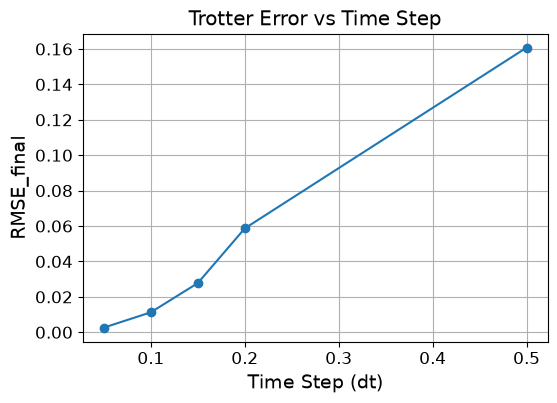

In [ ]:
plt.figure(figsize=(6,4))

plt.plot(
    df["dt"],
    df["RMSE_final"],
    'o-'
)

plt.xlabel("Time Step (dt)", fontsize=14)
plt.ylabel("RMSE_final", fontsize=14)
plt.title("Trotter Error vs Time Step", fontsize=14.5)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid()

# 1. Save as PNG (dpi=300 for crisp quality, bbox_inches='tight' prevents edge cropping)
plt.savefig('trotter_error_plot.png', bbox_inches='tight', dpi=300)
plt.savefig('trotter_error_plot.pdf', bbox_inches='tight', dpi=300)

plt.show()

In general, a smaller timestep should give a better approximation to the exact evolution. We compare the RMSE across several timesteps to see whether that trend appears in our results.

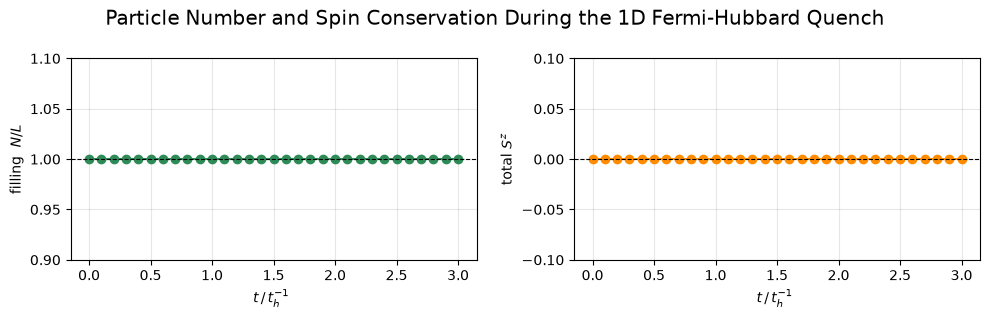

filling drift over the whole run: 2.22e-16
S^z    drift over the whole run: 2.22e-16


In [ ]:
dt_plot = 0.1
n_max_plot = 30
times = np.arange(n_max_plot + 1) * dt_plot

# Recalculate nup_q and ndn_q for the current dt_plot and n_max_plot
# We need H_exact and psi0 to be defined in the global scope
H_exact = H_qubitized(L, t_h, U, mu) # Redefine if not globally accessible
psi0    = np.zeros(2**N_Q, dtype=complex) # Redefine if not globally accessible
psi0[int(''.join(map(str, init_occ)), 2)] = 1.0 # Redefine if not globally accessible

_, _, nup_q, ndn_q, _, _ = run_simulation(dt_plot, n_max_plot)

N_tot  = nup_q.sum(axis=1) + ndn_q.sum(axis=1)
Sz_tot = 0.5 * (nup_q.sum(axis=1) - ndn_q.sum(axis=1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(times, N_tot / L, 'o-', color='seagreen'); ax[0].axhline(1.0, ls='--', c='k', lw=.8)
ax[0].set_ylabel("filling  $N/L$"); ax[0].set_ylim(0.9, 1.1)
ax[1].plot(times, Sz_tot, 'o-', color='darkorange');  ax[1].axhline(0.0, ls='--', c='k', lw=.8)
ax[1].set_ylabel(r"total $S^z$"); ax[1].set_ylim(-0.1, 0.1)
for a in ax: a.set_xlabel(r"$t\,/\,t_h^{-1}$ "); a.grid(alpha=.3)

fig.suptitle(
    "Particle Number and Spin Conservation During the 1D Fermi-Hubbard Quench",
    fontsize=14.5
)


fig.tight_layout();

# Save figure as PNG
plt.savefig(
    "particle_number_spin_conservation.png",
    bbox_inches="tight",
    dpi=300
)

# Save figure as PDF
plt.savefig(
    "particle_number_spin_conservation.pdf",
    bbox_inches="tight",
    dpi=300
)

plt.show()

print(f"filling drift over the whole run: {np.abs(N_tot/L - 1).max():.2e}")
print(f"S^z    drift over the whole run: {np.abs(Sz_tot).max():.2e}")

In [ ]:
!pip install qiskit-aer

## Simulating Depolarizing Noise

This section studies how depolarizing noise affects the simulated Fermi–Hubbard dynamics. We compare an ideal simulator with noisy simulations at two error probabilities, using multiple random seeds to examine variation between runs.

In [ ]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.noise import depolarizing_error

qc = qv.qs.to_qiskit()
qc.measure_all()

In [ ]:
ideal_sim = AerSimulator()

error1_qubit = depolarizing_error(0.001, 1)

error2_qubit = depolarizing_error(0.001, 2)

noise_model = NoiseModel()

noise_model.add_all_qubit_quantum_error(error1_qubit, ['rx', 'ry', 'rz', 'h', 'x'])

noise_model.add_all_qubit_quantum_error(error2_qubit, ['cx', 'cz', 'swap'])

noisy_sim = AerSimulator(noise_model=noise_model)

In [ ]:
error1_qubit_1pct = depolarizing_error(0.01, 1)
error2_qubit_1pct = depolarizing_error(0.01, 2)

noise_model_1pct = NoiseModel()

noise_model_1pct.add_all_qubit_quantum_error(
    error1_qubit_1pct,
    ['rx', 'ry', 'rz', 'h', 'x']
)

noise_model_1pct.add_all_qubit_quantum_error(
    error2_qubit_1pct,
    ['cx', 'cz', 'swap']
)

noisy_sim_1pct = AerSimulator(
    noise_model=noise_model_1pct
)

### Repeated Noisy Simulations

Each noise level is simulated with 4,096 shots per run and five different simulator seeds. We calculate the mean site occupations and their standard deviations to summarize the results across runs.

In [ ]:
seeds = [1234, 5678, 9012, 3456, 7890]

noisy_up_runs = []
noisy_down_runs = []
noisy_total_runs = []

for seed in seeds:

  noisy_result = noisy_sim.run(qc, shots=4096, seed_simulator=seed).result()

  noisy_counts = noisy_result.get_counts()

  noisy_up, noisy_down = occupations_from_counts(noisy_counts, flipped=False)

  noisy_total = noisy_up + noisy_down

  noisy_up_runs.append(noisy_up)
  noisy_down_runs.append(noisy_down)
  noisy_total_runs.append(noisy_total)


ideal_result = ideal_sim.run(qc, shots=4096, seed_simulator=1234).result()


ideal_counts = ideal_result.get_counts()

In [ ]:
noisy_total_runs_1pct = []

for seed in seeds:

    noisy_result = noisy_sim_1pct.run(
        qc,
        shots=4096,
        seed_simulator=seed
    ).result()

    noisy_counts = noisy_result.get_counts()

    noisy_up, noisy_down = occupations_from_counts(
        noisy_counts,
        flipped=False
    )

    noisy_total = noisy_up + noisy_down

    noisy_total_runs_1pct.append(noisy_total)

noisy_total_runs_1pct = np.array(noisy_total_runs_1pct)

mean_total_1pct = np.mean(
    noisy_total_runs_1pct,
    axis=0
)

std_total_1pct = np.std(
    noisy_total_runs_1pct,
    axis=0,
    ddof=1
)

In [ ]:
ideal_up, ideal_down = occupations_from_counts(ideal_counts, flipped=False)

In [ ]:
noisy_up_runs = np.array(noisy_up_runs)
noisy_down_runs = np.array(noisy_down_runs)
noisy_total_runs = np.array(noisy_total_runs)

In [ ]:
mean_up = np.mean(noisy_up_runs, axis=0)
std_up = np.std(noisy_up_runs, axis=0, ddof=1)

mean_down = np.mean(noisy_down_runs, axis=0)
std_down = np.std(noisy_down_runs, axis=0, ddof=1)

mean_total = np.mean(noisy_total_runs, axis=0)
std_total = np.std(noisy_total_runs, axis=0, ddof=1)

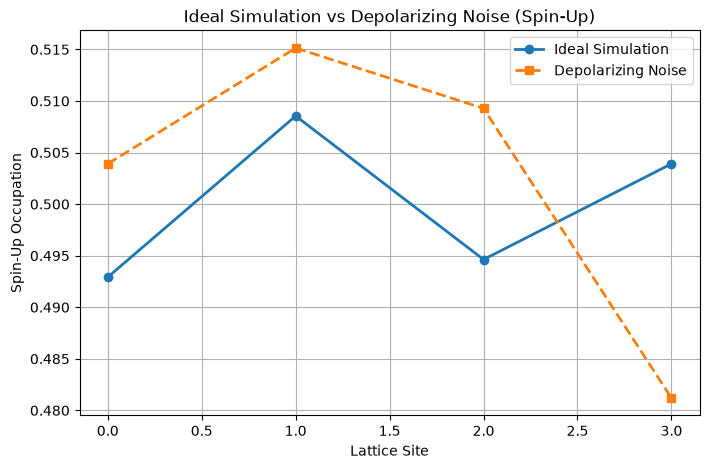

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    range(L),
    ideal_up,
    'o-',
    linewidth=2,
    label="Ideal Simulation"
)

plt.plot(
    range(L),
    mean_up,
    's--',
    linewidth=2,
    label="Depolarizing Noise (Mean)"
)

plt.xlabel("Lattice Site")
plt.ylabel("Spin-Up Occupation")
plt.title("Ideal Simulation vs Depolarizing Noise (Spin-Up)")
plt.legend()

plt.grid()

# 1. Save as PNG (dpi=300 for crisp quality, bbox_inches='tight' prevents edge cropping)
plt.savefig('spin_up_occupation_plot.png', bbox_inches='tight', dpi=300)
plt.savefig('spin_up_occupation_plot.pdf', bbox_inches='tight', dpi=300)

plt.show()

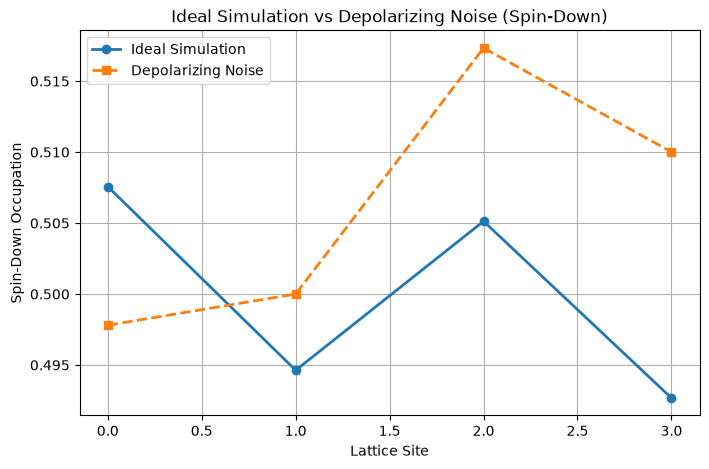

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    range(L),
    ideal_down,
    'o-',
    linewidth=2,
    label="Ideal Simulation"
)

plt.plot(
    range(L),
    mean_down,
    's--',
    linewidth=2,
    label="Depolarizing Noise (Mean)"
)

plt.xlabel("Lattice Site")
plt.ylabel("Spin-Down Occupation")
plt.title("Ideal Simulation vs Depolarizing Noise (Spin-Down)")
plt.legend()

plt.grid()

# 1. Save as PNG (dpi=300 for crisp quality, bbox_inches='tight' prevents edge cropping)
plt.savefig('spin_down_occupation_plot.png', bbox_inches='tight', dpi=300)
plt.savefig('spin_down_occupation_plot.pdf', bbox_inches='tight', dpi=300)

plt.show()

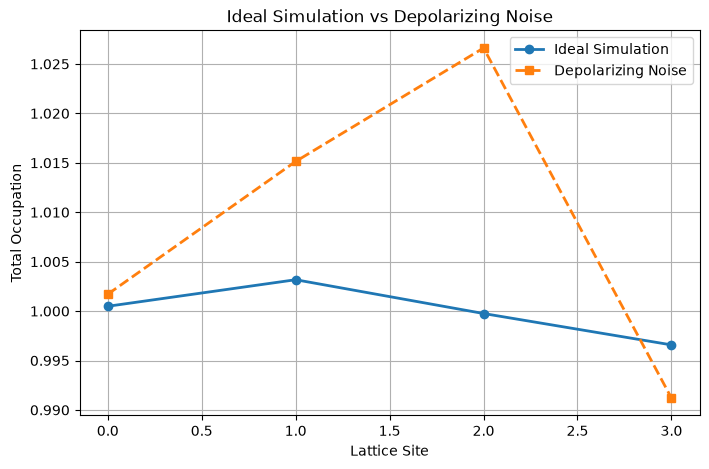

In [ ]:
ideal_total = ideal_up + ideal_down
noisy_total = noisy_up + noisy_down

plt.figure(figsize=(8,5))

plt.plot(
    range(L),
    ideal_total,
    'o-',
    linewidth=2,
    label="Ideal Simulation"
)

plt.plot(
    range(L),
    mean_total,
    's--',
    linewidth=2,
    label="Depolarizing Noise (Mean)"
)

plt.xlabel("Lattice Site")
plt.ylabel("Total Occupation")
plt.title("Ideal Simulation vs Depolarizing Noise")
plt.legend()

plt.grid()


# 1. Save as PNG (dpi=300 for crisp quality, bbox_inches='tight' prevents edge cropping)
plt.savefig('ideal_vs_depolarizing_comb_plot.png', bbox_inches='tight', dpi=300)
plt.savefig('ideal_vs_depolarizing_comb_plot.pdf', bbox_inches='tight', dpi=300)

plt.show()

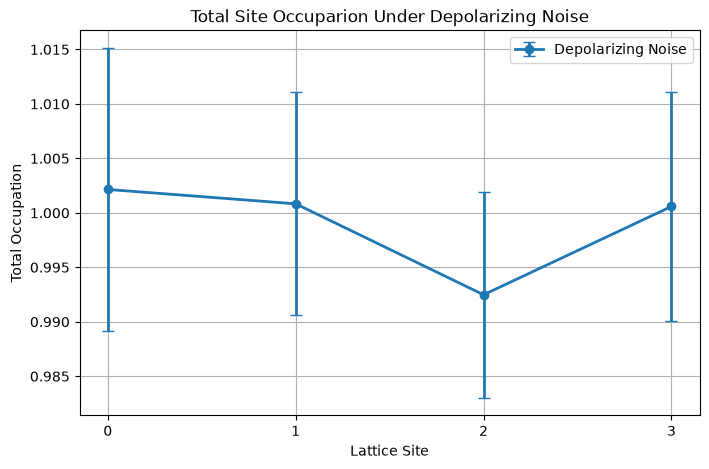

In [ ]:
sites = np.arange(L)

plt.figure(figsize=(8,5))

plt.errorbar(
    sites,
    mean_total,
    yerr=std_total,
    fmt='o-',
    capsize=4,
    linewidth=2,
    label="Depolarizing Noise"
)

plt.xlabel("Lattice Site")
plt.ylabel("Total Occupation")
plt.title("Total Site Occupation Under Depolarizing Noise")

plt.xticks(sites)
plt.legend()

plt.grid()

# 1. Save as PNG (dpi=300 for crisp quality, bbox_inches='tight' prevents edge cropping)
plt.savefig('depolarizing_SD_plot.png', bbox_inches='tight', dpi=300)
plt.savefig('depolarizing_SD_plot.pdf', bbox_inches='tight', dpi=300)

plt.show()

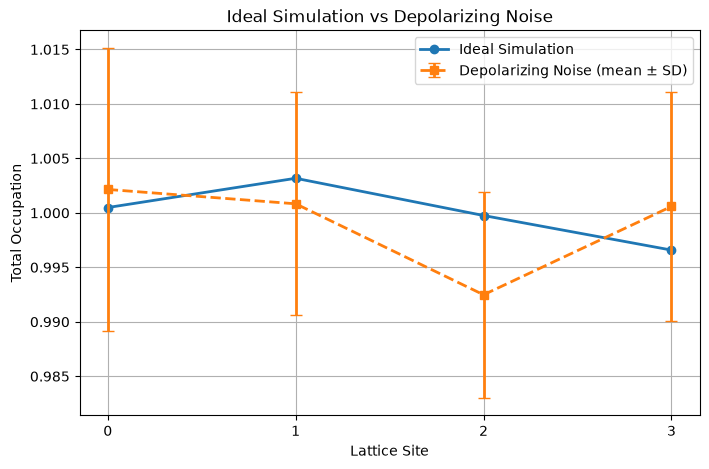

In [ ]:
ideal_total = ideal_up + ideal_down

plt.figure(figsize=(8,5))

plt.plot(
    sites,
    ideal_total,
    'o-',
    linewidth=2,
    label="Ideal Simulation"
)

plt.errorbar(
    sites,
    mean_total,
    yerr=std_total,
    fmt='s--',
    capsize=4,
    linewidth=2,
    label="Depolarizing Noise (mean ± SD)"
)

plt.xlabel("Lattice Site")
plt.ylabel("Total Occupation")
plt.title("Ideal Simulation vs Depolarizing Noise")

plt.xticks(sites)
plt.legend()

plt.grid()

# 1. Save as PNG (dpi=300 for crisp quality, bbox_inches='tight' prevents edge cropping)
plt.savefig('ideal_vs_depolarizing_SD_plot.png', bbox_inches='tight', dpi=300)
plt.savefig('ideal_vs_depolarizing_SD_plot.pdf', bbox_inches='tight', dpi=300)

plt.show()

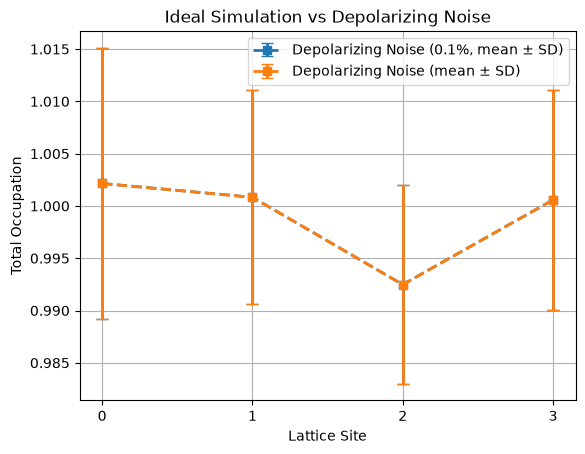

In [ ]:
plt.errorbar(
    sites,
    mean_total,
    yerr=std_total,
    fmt='s--',
    capsize=4,
    linewidth=2,
    label="Depolarizing Noise (0.1%, mean ± SD)"
)

plt.errorbar(
    sites,
    mean_total,
    yerr=std_total,
    fmt='s--',
    capsize=4,
    linewidth=2,
    label="Depolarizing Noise (mean ± SD)"
)

plt.xlabel("Lattice Site")
plt.ylabel("Total Occupation")
plt.title("Ideal Simulation vs Depolarizing Noise")

plt.xticks(sites)
plt.legend()

plt.grid()

# 1. Save as PNG (dpi=300 for crisp quality, bbox_inches='tight' prevents edge cropping)
plt.savefig('ideal_vs_depolarizing_SD_plot.png', bbox_inches='tight', dpi=300)
plt.savefig('ideal_vs_depolarizing_SD_plot.pdf', bbox_inches='tight', dpi=300)

plt.show()

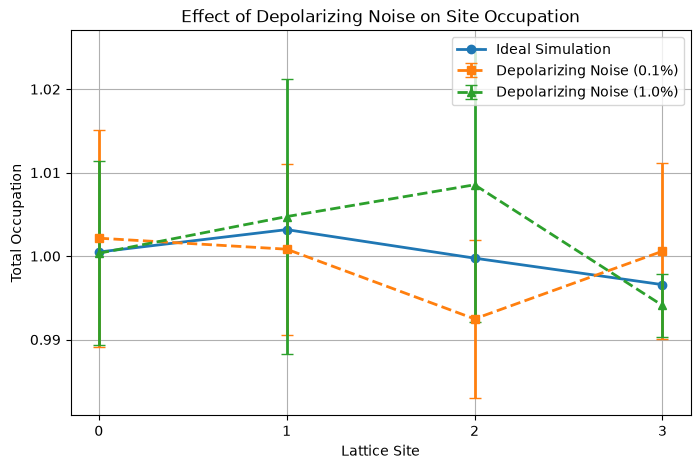

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    sites,
    ideal_total,
    'o-',
    linewidth=2,
    label="Ideal Simulation"
)

plt.errorbar(
    sites,
    mean_total,
    yerr=std_total,
    fmt='s--',
    capsize=4,
    linewidth=2,
    label="Depolarizing Noise (0.1%)"
)

plt.errorbar(
    sites,
    mean_total_1pct,
    yerr=std_total_1pct,
    fmt='^--',
    capsize=4,
    linewidth=2,
    label="Depolarizing Noise (1.0%)"
)

plt.xlabel("Lattice Site")
plt.ylabel("Total Occupation")

plt.title(
    "Effect of Depolarizing Noise on Site Occupation"
)

plt.xticks(sites)
plt.legend()
plt.grid()

plt.savefig(
    "depolarizing_noise_comparison.png",
    bbox_inches="tight",
    dpi=300
)

plt.savefig(
    "depolarizing_noise_comparison.pdf",
    bbox_inches="tight",
    dpi=300
)

plt.show()

RMSE for each noise level

### Comparing the Noise Levels

We calculate the root mean square error (RMSE) between the ideal and noisy total site occupations. This gives a compact measure of their difference, although the estimate also includes finite-shot sampling variation.

In [ ]:
rmse_01pct = np.sqrt(
    np.mean((mean_total - ideal_total) ** 2)
)

rmse_1pct = np.sqrt(
    np.mean((mean_total_1pct - ideal_total) ** 2)
)

print(f"RMSE at 0.1% noise: {rmse_01pct:.5f}")
print(f"RMSE at 1.0% noise:  {rmse_1pct:.5f}")

RMSE at 0.1% noise: 0.00439
RMSE at 1.0% noise:  0.00463


In [ ]:
results_table = pd.DataFrame({
    "Lattice Site": sites,
    "Ideal Occupation": ideal_total,
    "Noisy Mean": mean_total,
    "Noise SD": std_total
})

results_table = results_table.round({
    "Ideal Occupation": 3,
    "Noisy Mean": 3,
    "Noise SD": 3
})

print(results_table.to_string(index=False))

 Lattice Site  Ideal Occupation  Noisy Mean  Noise SD
            0             1.000       1.002     0.013
            1             1.003       1.001     0.010
            2             1.000       0.992     0.009
            3             0.997       1.001     0.011


In [ ]:
# 1. Set up figure
fig, ax = plt.subplots(
    figsize=(7, len(results_table) * 0.5 + 1),
    dpi=300
)

ax.axis('off')

# 2. Create table
table = ax.table(
    cellText=results_table.values,
    colLabels=results_table.columns,
    cellLoc='center',
    loc='center'
)

# 3. Format text and spacing
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)

# 4. Style table
header_color = '#1f4e78'
zebra_color = '#f2f6fa'

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#d0d7de')

    if row == 0:
        # Header
        cell.set_facecolor(header_color)
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
    else:
        # Alternating row colors
        cell.set_facecolor(
            zebra_color if row % 2 == 0 else '#ffffff'
        )
        cell.get_text().set_color('#222222')

# 5. Save as PNG
plt.savefig(
    'depolarizing_noise_results_table.png',
    bbox_inches='tight',
    dpi=300
)

# 6. Save as PDF
plt.savefig(
    'depolarizing_noise_results_table.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.close()

print("Table saved as PNG and PDF.")

Table saved as PNG and PDF.


In [ ]:
print(qv.qs.data)
print(type(qv.qs))
print(dir(qv.qs))

[qb_alloc(Qubit(qv.0)), qb_alloc(Qubit(qv.1)), qb_alloc(Qubit(qv.2)), qb_alloc(Qubit(qv.3)), qb_alloc(Qubit(qv.4)), qb_alloc(Qubit(qv.5)), qb_alloc(Qubit(qv.6)), qb_alloc(Qubit(qv.7)), x(Qubit(qv.0)), x(Qubit(qv.2)), x(Qubit(qv.4)), x(Qubit(qv.6)), rz(Qubit(qv.0)), rz(Qubit(qv.1)), rz(Qubit(qv.2)), rz(Qubit(qv.3)), rz(Qubit(qv.4)), rz(Qubit(qv.5)), rz(Qubit(qv.6)), rz(Qubit(qv.7)), h(Qubit(qv.1)), h(Qubit(qv.2)), rzz(Qubit(qv.1), Qubit(qv.2)), h(Qubit(qv.1)), h(Qubit(qv.2)), rx(Qubit(qv.1)), rx(Qubit(qv.2)), rzz(Qubit(qv.1), Qubit(qv.2)), rx(Qubit(qv.1)), rx(Qubit(qv.2)), h(Qubit(qv.3)), h(Qubit(qv.4)), rzz(Qubit(qv.3), Qubit(qv.4)), h(Qubit(qv.3)), h(Qubit(qv.4)), rx(Qubit(qv.3)), rx(Qubit(qv.4)), rzz(Qubit(qv.3), Qubit(qv.4)), rx(Qubit(qv.3)), rx(Qubit(qv.4)), h(Qubit(qv.5)), h(Qubit(qv.6)), rzz(Qubit(qv.5), Qubit(qv.6)), h(Qubit(qv.5)), h(Qubit(qv.6)), rx(Qubit(qv.5)), rx(Qubit(qv.6)), rzz(Qubit(qv.5), Qubit(qv.6)), rx(Qubit(qv.5)), rx(Qubit(qv.6)), rzz(Qubit(qv.0), Qubit(qv.1)), rz

### Circuit-Depth Analysis

Circuit depth provides a rough indication of the resources required to run the simulation. Smaller Trotter timesteps generally require more steps and therefore deeper circuits, creating a trade-off between approximation accuracy and circuit cost.

In [ ]:
def circuit_depths(qv):

    circuit = qv.qs

    # Total circuit depth
    total_depth = circuit.depth()

    # Two-qubit circuit depth
    def two_qubit_depth_indicator(operation):

        return 1 if operation.num_qubits == 2 else 0

    two_qubit_depth = circuit.depth(
        depth_indicator=two_qubit_depth_indicator
    )

    return total_depth, two_qubit_depth

In [ ]:
qv = build_circuit(
    dt=0.05,
    n_steps=40,
    init_occ=init_occ
)

total_depth, two_qubit_depth = circuit_depths(qv)

print("Total circuit depth:", total_depth)
print("Two-qubit circuit depth:", two_qubit_depth)

Total circuit depth: 1161
Two-qubit circuit depth: 560


In [ ]:
dt_values = [0.05, 0.10, 0.15, 0.20, 0.50]

summary = []

for dt in dt_values:

    # Final simulation time = 3.0
    n_max = int(3.0 / dt)

    # Number of Trotter steps required to reach t = 2
    n_2 = int(2.0 / dt)

    # Circuit at t = 2
    qv_t2 = build_circuit(
        dt,
        n_2,
        init_occ
    )

    total_depth_t2, two_qubit_depth_t2 = circuit_depths(qv_t2)

    # Circuit at final time
    qv_final = build_circuit(
        dt,
        n_max,
        init_occ
    )

    total_depth_final, two_qubit_depth_final = circuit_depths(qv_final)

    summary.append({

        "dt": dt,

        "time_t2": 2.0,
        "total_depth_t2": total_depth_t2,
        "two_qubit_depth_t2": two_qubit_depth_t2,

        "final_time": dt * n_max,
        "total_depth_final": total_depth_final,
        "two_qubit_depth_final": two_qubit_depth_final
    })

depth_df = pd.DataFrame(summary)

print(depth_df)

     dt  time_t2  total_depth_t2  two_qubit_depth_t2  final_time  \
0  0.05      2.0            1161                 560         3.0   
1  0.10      2.0             581                 280         3.0   
2  0.15      2.0             378                 182         3.0   
3  0.20      2.0             291                 140         3.0   
4  0.50      2.0             117                  56         3.0   

   total_depth_final  two_qubit_depth_final  
0               1741                    840  
1                871                    420  
2                581                    280  
3                436                    210  
4                175                     84  


### Trotter error scaling

The mirrored/palindromic step should give a **global** error $\mathcal{O}(\Delta t^2)$ — halving
$\Delta t$ should cut the error by roughly four.

In [ ]:
T = 1.0
print(f"  {'n_steps':>8}  {'dt':>7}   {'||psi_trotter - psi_exact||':>28}   {'ratio':>6}")
prev = None
psi_ex = la.expm(-1j * H_exact * T) @ psi0
for n_steps in [2, 4, 8, 16, 32]:
    d = T / n_steps
    sv = build_circuit(d, n_steps, init_occ).qs.statevector("array")
    # remove global phase before comparing
    ov = np.vdot(psi_ex, sv)
    err = np.linalg.norm(sv - psi_ex * ov / abs(ov))
    ratio = "" if prev is None else f"{prev/err:5.2f}x"
    print(f"  {n_steps:>8}  {d:>7.4f}   {err:>28.3e}   {ratio:>6}")
    prev = err
print("\nratios near 4 confirm the O(dt^2) global scaling of the mirrored step.")

   n_steps       dt    ||psi_trotter - psi_exact||    ratio
         2   0.5000                      1.086e+00         
         4   0.2500                      3.221e-01    3.37x
         8   0.1250                      7.821e-02    4.12x
        16   0.0625                      1.933e-02    4.05x
        32   0.0312                      4.818e-03    4.01x

ratios near 4 confirm the O(dt^2) global scaling of the mirrored step.


---
## 8. Running it on hardware

Everything above used Qrisp's local simulator (`get_measurement()` with no backend). To send the
same circuits to IQM, pass a backend — the circuit code does not change:

```python
from pathlib import Path
from qrisp.interface import IQMBackend

token = Path.home().joinpath(".iqm_token").read_text().strip()

backend = IQMBackend(
    api_token=token,
    device_instance="garnet",     # Crystal architecture: no MOVE gates
)

counts = qv.get_measurement(backend=backend, shots=4000)
```

**Three practical notes.**

*Device choice.* Star-architecture devices (Deneb, Sirius) route two-qubit gates through a central
resonator using MOVE gates, which Qrisp's Qiskit converter does not currently recognise. Crystal
devices (Garnet, Garnet) are square lattices with no resonator, so the round trip works. That is
convenient here anyway: this circuit is a 1D chain, so it only ever needs nearest-neighbour
connectivity, and all-to-all buys us nothing.

*Circuit size.* $L=4$ needs 8 qubits and about 12 two-qubit gates per Trotter step after
compilation. Twenty steps is roughly 240 entangling gates — deep enough that on current hardware
the occupations will visibly decay toward $1/2$ (the maximally-mixed value) rather than tracking
the exact curve. Start with 2–5 steps.

*What to expect.* Compare the hardware curve against the `nup_e`/`ndn_e` reference already computed
above. Two error sources are mixed together in the gap: Trotter error, which you control with
$\Delta t$, and hardware noise, which you don't. Separating them is the point of the error
suppression and post-processing machinery in Sec. IV of the paper — readout-error mitigation,
decay recovery, and post-selection on the conserved $N$ and $S^z$ we plotted above. That last one
is nearly free here and worth doing first: discard any shot whose total particle number isn't $L$.

## IQM Hardware Execution

This section extends the Fermi–Hubbard simulation to IQM quantum hardware. The same circuit parameters and initial Néel state are used to compare results from the Garnet and Emerald processors.

In [ ]:

# Install IQM dependencies if they are not already available.
%pip install -U "iqm-client>=35.0.0" "qrisp[iqm]"

import os
from qrisp.interface import IQMBackend

# Load the API token from an environment variable.
# Never store API credentials directly in a notebook or GitHub repository.
api_token = os.getenv("IQM_API_TOKEN")

if not api_token:
    raise ValueError(
        "IQM_API_TOKEN environment variable is not set. "
        "Set it before connecting to IQM Resonance."
    )

# IQM Resonance connection settings.
server_url = "https://resonance.iqm.tech/"

# Set use_timeslot=True if you have booked a timeslot.
garnet_backend = IQMBackend(
    api_token=api_token,
    server_url=server_url,
    device_instance="garnet",
    use_timeslot=False
)

emerald_backend = IQMBackend(
    api_token=api_token,
    server_url=server_url,
    device_instance="emerald",
    use_timeslot=False
)

### Repeated Hardware Measurements

To examine the consistency of the hardware results, each circuit is executed across multiple independent runs. The site occupations are averaged across runs, and their standard deviations are calculated to show the variation in the measurements.

In [ ]:
# Choose experimental parameters
dt = 0.10

# Example: hardware run at t = 3
n_steps = int(3.0 / dt)

qv = build_circuit(
    dt=dt,
    n_steps=n_steps,
    init_occ=init_occ
)


# Garnet


counts_garnet = qv.get_measurement(
    backend=garnet_backend,
    shots=4000
)

nup_garnet, ndn_garnet = occupations_from_counts(
    counts_garnet,
    flipped=(n_steps % 2 == 1)
)

nup_garnet = np.array(nup_garnet)
ndn_garnet = np.array(ndn_garnet)
total_garnet = nup_garnet + ndn_garnet



# Emerald


counts_emerald = qv.get_measurement(
    backend=emerald_backend,
    shots=4000
)

nup_emerald, ndn_emerald = occupations_from_counts(
    counts_emerald,
    flipped=(n_steps % 2 == 1)
)

nup_emerald = np.array(nup_emerald)
ndn_emerald = np.array(ndn_emerald)
total_emerald = nup_emerald + ndn_emerald


print("Garnet total occupation:")
print(total_garnet)

print("\nEmerald total occupation:")
print(total_emerald)

Progress in queue:   0%|          | 0/1 [00:00<?, ?it/s]

Progress in queue:   0%|          | 0/2 [00:00<?, ?it/s]

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sites = np.arange(L)

plt.figure(figsize=(8, 5))

plt.plot(
    sites,
    total_garnet,
    "o-",
    linewidth=2,
    label="IQM Garnet"
)

plt.plot(
    sites,
    total_emerald,
    "s-",
    linewidth=2,
    label="IQM Emerald"
)

plt.xlabel("Lattice Site")
plt.ylabel("Total Occupation")
plt.title("IQM Hardware Comparison at t = 3.0")

plt.xticks(sites)
plt.legend()
plt.grid()

plt.savefig(
    "garnet_vs_emerald.png",
    bbox_inches="tight",
    dpi=300
)

plt.savefig(
    "garnet_vs_emerald.pdf",
    bbox_inches="tight",
    dpi=300
)

plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 1. Hardware Excution - 5 runs
target_time = 3.0
n_steps = int(target_time / dt)  # 30 steps
shots = 4096
num_runs = 5  # Replicating 5 independent hardware executions


# Storage


garnet_total_runs = []
emerald_total_runs = []



# Garnet runs

for i in range(num_runs):

    print(f"Garnet run {i+1}/{num_runs}")

    qv = build_circuit(
        dt=dt,
        n_steps=n_steps,
        init_occ=init_occ
    )

    counts = qv.get_measurement(
        backend=garnet_backend,
        shots=shots
    )

    nup, ndn = occupations_from_counts(
        counts,
        flipped=(n_steps % 2 == 1)
    )

    total = np.array(nup) + np.array(ndn)

    garnet_total_runs.append(total)


# -----------------------------
# Emerald runs
# -----------------------------

for i in range(num_runs):

    print(f"Emerald run {i+1}/{num_runs}")

    qv = build_circuit(
        dt=dt,
        n_steps=n_steps,
        init_occ=init_occ
    )

    counts = qv.get_measurement(
        backend=emerald_backend,
        shots=shots
    )

    nup, ndn = occupations_from_counts(
        counts,
        flipped=(n_steps % 2 == 1)
    )

    total = np.array(nup) + np.array(ndn)

    emerald_total_runs.append(total)

garnet_total_runs = np.array(garnet_total_runs)
emerald_total_runs = np.array(emerald_total_runs)

garnet_mean = np.mean(garnet_total_runs, axis=0)
garnet_std = np.std(garnet_total_runs, axis=0, ddof=1)

emerald_mean = np.mean(emerald_total_runs, axis=0)
emerald_std = np.std(emerald_total_runs, axis=0, ddof=1)

plt.figure(figsize=(9, 5))

plt.plot(
    sites,
    ideal_total,
    "o-",
    linewidth=2,
    label="Ideal Simulation"
)

plt.errorbar(
    sites,
    mean_total,
    yerr=std_total,
    fmt="s--",
    capsize=4,
    linewidth=2,
    label="Depolarizing Noise"
)

plt.errorbar(
    sites,
    garnet_mean,
    yerr=garnet_std,
    fmt="^-",
    capsize=4,
    linewidth=2,
    label="IQM Garnet"
)

plt.errorbar(
    sites,
    emerald_mean,
    yerr=emerald_std,
    fmt="D-",
    capsize=4,
    linewidth=2,
    label="IQM Emerald"
)

plt.xlabel("Lattice Site")
plt.ylabel("Total Occupation")
plt.title("Fermi-Hubbard Occupation: Simulation vs IQM Hardware")

plt.xticks(sites)
plt.legend()
plt.grid()

plt.savefig(
    "simulation_vs_garnet_vs_emerald.png",
    bbox_inches="tight",
    dpi=300
)

plt.savefig(
    "simulation_vs_garnet_vs_emerald.pdf",
    bbox_inches="tight",
    dpi=300
)

plt.show()

### Simulation and Hardware Comparison

The total site occupations from the ideal simulation, depolarizing noise model, and IQM hardware executions are compared at the same target simulation time. This comparison helps evaluate how closely the hardware results reproduce the expected Fermi–Hubbard dynamics.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd



# 1. Combined Comparison Plot


plt.figure(figsize=(9, 5.5))

# Ideal Simulation
plt.plot(
    sites,
    ideal_total,
    'o-',
    linewidth=2,
    label="Ideal Simulation"
)

# 0.1% Depolarizing Noise
plt.errorbar(
    sites,
    mean_total,
    yerr=std_total,
    fmt='s--',
    capsize=4,
    linewidth=2,
    label="Depolarizing Noise (0.1%, mean ± SD)"
)

# IQM Garnet Hardware
plt.errorbar(
    sites,
    garnet_mean,
    yerr=garnet_std,
    fmt='^-',
    capsize=4,
    linewidth=2,
    label="IQM Garnet (mean ± SD)"
)

# IQM Emerald Hardware
plt.errorbar(
    sites,
    emerald_mean,
    yerr=emerald_std,
    fmt='D-',
    capsize=4,
    linewidth=2,
    label="IQM Emerald (mean ± SD)"
)


plt.xlabel("Lattice Site")
plt.ylabel("Total Occupation")
plt.title("Total Occupation Comparison at t = 3.0")

plt.xticks(sites)
plt.legend()
plt.grid()

plt.savefig(
    'ideal_noise_garnet_emerald_comparison.png',
    bbox_inches='tight',
    dpi=300
)

plt.savefig(
    'ideal_noise_garnet_emerald_comparison.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()


# 2. Comparison Summary Table

comparison_table = pd.DataFrame({
    "Lattice Site": sites,

    "Ideal Occupation": ideal_total,

    "0.1% Noise Mean": mean_total,
    "0.1% Noise SD": std_total,

    "Garnet Mean": garnet_mean,
    "Garnet SD": garnet_std,

    "Emerald Mean": emerald_mean,
    "Emerald SD": emerald_std
})


comparison_table = comparison_table.round({
    "Ideal Occupation": 3,

    "0.1% Noise Mean": 3,
    "0.1% Noise SD": 3,

    "Garnet Mean": 3,
    "Garnet SD": 3,

    "Emerald Mean": 3,
    "Emerald SD": 3
})


print("\n--- Complete Benchmark Summary ---")
print(comparison_table.to_string(index=False))

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


# 1. Results

results_table = pd.DataFrame({
    "Lattice Site": sites,
    "Ideal Occupation": ideal_total,
    "Noisy Mean": mean_total,
    "Noisy SD": std_total,
    #"Hardware Mean": mean_hw_total,
    #"Hardware SD": std_hw_total
})

# Round numeric values for clean table display
results_table = results_table.round({
    "Ideal Occupation": 3,
    "Noisy Mean": 3,
    "Noisy SD": 3,
    "Hardware Mean": 3,
    "Hardware SD": 3
})

fig, ax = plt.subplots(
    figsize=(9, len(results_table) * 0.5 + 1.2),
    dpi=300
)

ax.axis('off')

#Table created

table = ax.table(
    cellText=results_table.values,
    colLabels=results_table.columns,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)


header_color = '#1f4e78'
zebra_color = '#f2f6fa'

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#d0d7de')

    if row == 0:
        # Header Styling
        cell.set_facecolor(header_color)
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
    else:
        # Alternating Row Colors (Zebra Striping)
        cell.set_facecolor(
            zebra_color if row % 2 == 0 else '#ffffff'
        )
        cell.get_text().set_color('#222222')

#Save

plt.savefig(
    'ideal_vs_noise_vs_hardware_results_table.png',
    bbox_inches='tight',
    dpi=300
)

plt.savefig(
    'ideal_vs_noise_vs_hardware_results_table.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.close()

print("Comparison table successfully saved as PNG and PDF.")

Readout Error Mitigation on IQM Garnet
## Readout Error Mitigation

This section investigates a per-qubit readout correction method using calibration measurements. The calibration results are used to estimate measurement errors and correct the measured occupation probabilities. The current experiment uses a simulated readout-error model rather than calibration data collected directly from IQM hardware.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dt = 0.10
n_steps = int(3.0 / dt)

shots = 4096

print(f"dt = {dt}")
print(f"Trotter steps = {n_steps}")
print(f"Total simulation time = {dt * n_steps}")
print(f"Shots = {shots}")

In [ ]:
qv = build_circuit(
    dt=dt,
    n_steps=n_steps,
    init_occ=init_occ
)

qc = qv.qs.to_qiskit()
qc.measure_all()

print("Circuit depth:", qc.depth())
print("Number of gates:", len(qc.data))

In [ ]:
#Run Ideal Simulation

ideal_result = ideal_sim.run(
    qc,
    shots=shots,
    seed_simulator=1234
).result()

ideal_counts = ideal_result.get_counts()

ideal_up, ideal_down = occupations_from_counts(
    ideal_counts,
    flipped=(n_steps % 2 == 1)
)

ideal_total = ideal_up + ideal_down

print("Ideal total occupation:")
print(ideal_total)

In [ ]:
#Depolarizing Noise Simulation

seeds = [1234, 5678, 9012, 3456, 7890]

noisy_total_runs = []

for seed in seeds:

    noisy_result = noisy_sim.run(
        qc,
        shots=shots,
        seed_simulator=seed
    ).result()

    noisy_counts = noisy_result.get_counts()

    noisy_up, noisy_down = occupations_from_counts(
        noisy_counts,
        flipped=(n_steps % 2 == 1)
    )

    noisy_total_runs.append(noisy_up + noisy_down)

#noisy_total_runs = np.mean(noisy_total_runs)

noisy_total_runs = np.array(noisy_total_runs)

noisy_mean = np.mean(noisy_total_runs, axis=0)
noisy_std = np.std(noisy_total_runs, axis=0, ddof=1)

print("Noisy mean:")
print(noisy_mean)
print("\nNoisy standard deviation:")
print(noisy_std)

print("Depolarizing Noise total occupation:")
print(noisy_total)

In [ ]:
#Calibration Circuits

from qiskit import QuantumCircuit

def create_readout_calibration_circuits(n_qubits):

  circuits = []

  #Prepare |000...0>
  qc0 = QuantumCircuit(n_qubits, n_qubits)

  for q in range(n_qubits):
    qc0.measure(q, q)

  circuits.append(qc0)

  #Prepare |111...1>
  qc1 = QuantumCircuit(n_qubits, n_qubits)

  for q in range(n_qubits):
    qc1.x(q)

  for q in range(n_qubits):
    qc1.measure(q, q)

  circuits.append(qc1)

  return circuits

In [ ]:
#Run Calibration on Noisy Simulator

calibration_circuits = create_readout_calibration_circuits(N_Q)

calibration_results = noisy_sim.run(
    calibration_circuits,
    shots=shots,
    seed_simulator=1234
).result()

cal_zero_counts = calibration_results.get_counts(0)
cal_one_counts = calibration_results.get_counts(1)

print("Calibration |000...0|:")
print(cal_zero_counts)

print("\nCalibration |111...1|:")
print(cal_one_counts)

In [ ]:
#Estimate Readout Errors

def get_bit_probabilities(counts, n_qubits):

  probabilities = np.zeros(n_qubits)

  total_shots = sum(counts.values())

  for bitstring, count in counts.items():

    probability = count / total_shots

    #Reverse Qiskit bitstrong ordering
    bitstring = bitstring[::-1]

    for q in range(n_qubits):

      if bitstring[q] == "1":
        probabilities[q] += probability

  return probabilities


In [ ]:
p1_when_zero = get_bit_probabilities(cal_zero_counts, N_Q)
p1_when_one = get_bit_probabilities(cal_one_counts, N_Q)

print("P(measured 1 | prepared 0):")
print(p1_when_zero)
print("\nP(measured 1 | prepared 1):")
print(p1_when_one)

In [ ]:
#Readout Error Mitigation

def mitigate_readout_probabilities(measured_probabilities, p1_when_zero, p1_when_one):

  corrected = np.zeros(len(measured_probabilities))

  for q in range(len(measured_probabilities)):
    a = p1_when_zero[q]
    b = p1_when_one[q]

    denominator = b - a

    if abs(denominator) < 1e-12:
      corrected[q] = measured_probabilities[q]
    else:
      corrected[q] = (measured_probabilities[q] - a) / denominator

  return np.clip(corrected, 0, 1)

In [ ]:
#Measure Noisy Circuit

noisy_result = noisy_sim.run(
    qc,
    shots=shots,
    seed_simulator=1234
).result()

noisy_counts = noisy_result.get_counts()

measured_probabilities = get_bit_probabilities(
    noisy_counts,
    N_Q
)

mitigated_probabilities = mitigate_readout_probabilities(
    measured_probabilities,
    p1_when_zero,
    p1_when_one
)

print("Measured probabilities:")
print(measured_probabilities)

print("\nMitigated probabilities:")
print(mitigated_probabilities)

In [ ]:
#Convert Mitigated Qubit Proabilities to Site Occupations

mitigated_up = np.array([
    mitigated_probabilities[
        qubit_of(i, 'u')
    ]
    for i in range(L)
])

mitigated_down = np.array([
    mitigated_probabilities[
        qubit_of(i, 'd')
    ]
    for i in range(L)
])

mitigated_total = mitigated_up + mitigated_down

print("Mitigated spin-up:")
print(mitigated_up)

print("\nMitigated spin-down:")
print(mitigated_down)

print("\nMitigated total occupation:")
print(mitigated_total)

In [ ]:
#RMSE Comparison

rmse_noisy = np.sqrt(
    np.mean(
        (noisy_mean - ideal_total) ** 2
    )
)

rmse_mitigated = np.sqrt(
    np.mean(
        (mitigated_total - ideal_total) ** 2
    )
)

rmse_garnet = np.sqrt(
    np.mean(
        (total_garnet - ideal_total) ** 2
    )
)

rmse_emerald = np.sqrt(
    np.mean(
        (total_emerald - ideal_total) ** 2
    )
)

print(f"RMSE - Depolarizing noise: {rmse_noisy:.5f}")
print(f"RMSE - Mitigated:           {rmse_mitigated:.5f}")
print(f"RMSE - Garnet hardware:     {rmse_garnet:.5f}")
print(f"RMSE - Emerald hardware:     {rmse_emerald:.5f}")

In [ ]:
#Error Reduction

if rmse_noisy > 0:

    improvement = (
        (rmse_noisy - rmse_mitigated)
        / rmse_noisy
    ) * 100

    print(f"Error reduction from mitigation: {improvement:.2f}%")

In [ ]:
#Comparison Table

comparison = pd.DataFrame({

    "Site": np.arange(L),

    "Ideal": ideal_total,

    "Depolarizing Noise": noisy_mean,

    "Mitigated": mitigated_total,

    "IQM Garnet": total_garnet,

    "IQM Emerald": total_emerald
})

comparison = comparison.round(3)

print(comparison)

In [ ]:
#Plots

sites = np.arange(L)

plt.figure(figsize=(9, 5))

plt.plot(
    sites,
    ideal_total,
    'o-',
    label="Ideal"
)

plt.plot(
    sites,
    noisy_mean,
    's--',
    label="Depolarizing Noise"
)

plt.plot(
    sites,
    mitigated_total,
    'D--',
    label="Mitigated"
)

plt.plot(
    sites,
    total_garnet,
    '^--',
    label="IQM Garnet"
)

plt.plot(
    sites,
    total_emerald,
    '^--',
    label="IQM Emerald"
)

plt.xlabel("Lattice Site")
plt.ylabel("Total Occupation")

plt.title(
    "Fermi-Hubbard Site Occupation: "
    "Ideal, Noisy, Mitigated, and Hardware"
)

plt.xticks(sites)
plt.grid()
plt.legend()

plt.show()

In [ ]:
import matplotlib.pyplot as plt

# 1. Define table data

headers = ["Trotter Step (dt)",
    "Total Circuit Depth",
    "Two-Qubit Circuit Depth"]

data = [
    [
        f"{row['dt']:.2f}",
        int(row["Total Circuit Depth"]),
        int(row["Two-Qubit Circuit Depth"])
    ]
    for _, row in depth_df.iterrows()
]


# 2. Set up figure canvas

fig, ax = plt.subplots(figsize=(7, 3.5), dpi=300)
ax.axis('off')


# 3. Add title

ax.set_title(
    "Circuit Depth at Final Time t = 3",
    fontsize=14.5,
    #fontweight='bold',
    #pad=20
)


# 4. Create matplotlib table

table = ax.table(
    cellText=data,
    colLabels=headers,
    cellLoc='center',
    loc='center'
)


# 5. Scale & format text

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 2.2)


# 6. Apply custom styling

header_color = '#1f4e78'
zebra_color = '#f2f6fa'
border_color = '#d0d7de'

for (row, col), cell in table.get_celld().items():

    cell.set_edgecolor(border_color)
    cell.set_linewidth(1)

    if row == 0:
        # Header
        cell.set_facecolor(header_color)
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
        cell.get_text().set_fontsize(12)

    else:
        # Alternating row colors
        if row % 2 == 0:
            cell.set_facecolor(zebra_color)
        else:
            cell.set_facecolor('#ffffff')

        cell.get_text().set_color('#222222')


# 7. Adjust layout

plt.tight_layout()


# 8. Save as PNG and PDF

plt.savefig(
    'circuit_depth_t3.png',
    bbox_inches='tight',
    dpi=300
)

plt.savefig(
    'circuit_depth_t3.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()

In [ ]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. PREPARE CIRCUIT DEPTH DATA (Simplified for t = 3.0)

dt_values = [0.05, 0.10, 0.15, 0.20, 0.50]
summary = []

for dt in dt_values:
    n_max = int(3.0 / dt)
    qv_final = build_circuit(dt, n_max, init_occ)
    total_depth_final, two_qubit_depth_final = circuit_depths(qv_final)

    summary.append({
        "dt": dt,
        "Target Time (t)": 3.0,
        "Trotter Steps (N)": n_max,
        "Total Circuit Depth": total_depth_final,
        "Two-Qubit Circuit Depth": two_qubit_depth_final
    })

depth_df = pd.DataFrame(summary)

# 2. CREATE UNIFIED FIGURE LAYOUT WITH PADDED MARGINS

# Increased figure width slightly to 17 to give the right side extra breathing room
fig = plt.figure(figsize=(17, 11), dpi=300)

# GridSpec with custom margins to shift right elements inward
gs = gridspec.GridSpec(
    2, 2,
    height_ratios=[1.8, 1.0],
    hspace=0.35,
    wspace=0.28,
    left=0.06,   # Extra space on left
    right=0.93,  # Prevents right-side clipping
    top=0.93,
    bottom=0.05
)


# TOP LEFT: Néel State Quench Dynamics

gs_top_left = gridspec.GridSpecFromSubplotSpec(
    2, 2, subplot_spec=gs[0, 0], hspace=0.32, wspace=0.25
)

axes_neel = [
    fig.add_subplot(gs_top_left[0, 0]),
    fig.add_subplot(gs_top_left[0, 1]),
    fig.add_subplot(gs_top_left[1, 0]),
    fig.add_subplot(gs_top_left[1, 1])
]

for i, ax in enumerate(axes_neel):
    ax.plot(times, nup_q[:, i], 'o-', ms=3.5, color='crimson', label=r'$\langle n_{\uparrow}\rangle$ Sim')
    ax.plot(times, ndn_q[:, i], 's-', ms=3.5, color='royalblue', label=r'$\langle n_{\downarrow}\rangle$ Sim')
    ax.plot(times, nup_e[:, i], '--', color='crimson', alpha=0.55, label='Exact')
    ax.plot(times, ndn_e[:, i], '--', color='royalblue', alpha=0.55)
    ax.plot(hardware_times, nup_hardware_history[:, i], 'o-', ms=3.5, linewidth=1.5, color='lightgreen', markeredgecolor='darkgreen', label=r'$\langle n_{\uparrow}\rangle$ HW')
    ax.plot(hardware_times, ndn_hardware_history[:, i], 's-', ms=3.5, linewidth=1.5, color='darkgreen', label=r'$\langle n_{\downarrow}\rangle$ HW')

    ax.set_title(f"Site {i}", fontsize=10, fontweight='bold')
    ax.grid(alpha=0.3)
    ax.set_ylim(-0.05, 1.05)

    if i in [2, 3]:
        ax.set_xlabel(r"Time $t/t_h^{-1}$", fontsize=9)
    if i in [0, 2]:
        ax.set_ylabel("Occupation", fontsize=9)

axes_neel[0].legend(fontsize=7, loc='lower right')

# TOP RIGHT: Total Occupation Comparison at t = 3.0

ax_comp = fig.add_subplot(gs[0, 1])

ax_comp.plot(sites, ideal_total, 'o-', linewidth=2, markersize=6, label="Ideal Simulation")
ax_comp.errorbar(sites, mean_total, yerr=std_total, fmt='s--', capsize=4, linewidth=2, markersize=6, label="Depolarizing Noise (mean ± SD)")
ax_comp.errorbar(sites, mean_hw_total, yerr=std_hw_total, fmt='^-', capsize=4, linewidth=2, markersize=6, label="IQM Hardware (mean ± SD)")

ax_comp.set_xlabel("Lattice Site", fontsize=10, fontweight='bold')
ax_comp.set_ylabel("Total Occupation", fontsize=10, fontweight='bold')
ax_comp.set_title("Total Occupation Comparison ($t = 3.0$)", fontsize=11, fontweight='bold')
ax_comp.set_xticks(sites)
ax_comp.grid(True, linestyle='--', alpha=0.5)
ax_comp.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9)


# BOTTOM: Circuit Depth Scaling Table (Contrained Width)

ax_table = fig.add_subplot(gs[1, :])
ax_table.axis('off')

table_data = ax_table.table(
    cellText=depth_df.values,
    colLabels=depth_df.columns,
    cellLoc='center',
    loc='center',
    colWidths=[0.12, 0.15, 0.18, 0.22, 0.25]  # Explicit column widths prevent rightward spill
)

table_data.auto_set_font_size(False)
table_data.set_fontsize(9.5)
table_data.scale(0.9, 1.8)

header_color = '#1f4e78'
zebra_color = '#f2f6fa'

for (row, col), cell in table_data.get_celld().items():
    cell.set_edgecolor('#d0d7de')
    if row == 0:
        cell.set_facecolor(header_color)
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
    else:
        cell.set_facecolor(zebra_color if row % 2 == 0 else '#ffffff')
        cell.get_text().set_color('#222222')

ax_table.set_title(
    "Circuit Depth Scaling vs. Trotter Step Size ($\Delta t$) at Target Time $t = 3.0$",
    fontsize=11,
    fontweight='bold',
    pad=12
)

# 3. SAVE

plt.savefig(
    "fermi_hubbard_unified_summary_page.png",
    bbox_inches='tight',
    pad_inches=0.2,  # Adds explicit outer padding to PDF rendering
    dpi=300
)

plt.savefig(
    "fermi_hubbard_unified_summary_page.pdf",
    bbox_inches='tight',
    pad_inches=0.2,
    dpi=300
)

plt.show()

In [ ]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 1. PREPARE CIRCUIT DEPTH DATA (Simplified for t = 3.0)

dt_values = [0.05, 0.10, 0.15, 0.20, 0.50]
summary = []

for dt in dt_values:
    n_max = int(3.0 / dt)
    qv_final = build_circuit(dt, n_max, init_occ)
    total_depth_final, two_qubit_depth_final = circuit_depths(qv_final)

    summary.append({
        "dt": dt,
        "Target Time (t)": 3.0,
        "Trotter Steps (N)": n_max,
        "Total Circuit Depth": total_depth_final,
        "Two-Qubit Circuit Depth": two_qubit_depth_final
    })

depth_df = pd.DataFrame(summary)


# 2. CREATE UNIFIED FIGURE LAYOUT WITH PADDED MARGINS

# Increased figure width slightly to 17 to give the right side extra breathing room
fig = plt.figure(figsize=(17, 11), dpi=300)

# GridSpec with custom margins to shift right elements inward
gs = gridspec.GridSpec(
    2, 2,
    height_ratios=[1.8, 1.0],
    hspace=0.35,
    wspace=0.28,
    left=0.06,   # Extra space on left
    right=0.93,  # Prevents right-side clipping
    top=0.93,
    bottom=0.05
)


# TOP LEFT: Néel State Quench Dynamics

ax_neel_title = fig.add_subplot(gs[0, 0])
ax_neel_title.axis('off')
ax_neel_title.set_title(
    "1D Fermi-Hubbard Quench from a Neel State",
    fontsize=11,
    fontweight='bold',
    pad=15
)

gs_top_left = gridspec.GridSpecFromSubplotSpec(
    2, 2, subplot_spec=gs[0, 0], hspace=0.32, wspace=0.25
)

axes_neel = [
    fig.add_subplot(gs_top_left[0, 0]),
    fig.add_subplot(gs_top_left[0, 1]),
    fig.add_subplot(gs_top_left[1, 0]),
    fig.add_subplot(gs_top_left[1, 1])
]

for i, ax in enumerate(axes_neel):
    ax.plot(times, nup_q[:, i], 'o-', ms=3.5, color='crimson', label=r'$\langle n_{\uparrow}\rangle$ Sim')
    ax.plot(times, ndn_q[:, i], 's-', ms=3.5, color='royalblue', label=r'$\langle n_{\downarrow}\rangle$ Sim')
    ax.plot(times, nup_e[:, i], '--', color='crimson', alpha=0.55, label='Exact')
    ax.plot(times, ndn_e[:, i], '--', color='royalblue', alpha=0.55)

    ax.set_title(f"Site {i}", fontsize=10, fontweight='bold')
    ax.grid(alpha=0.3)
    ax.set_ylim(-0.05, 1.05)

    if i in [2, 3]:
        ax.set_xlabel(r"Time $t/t_h^{-1}$", fontsize=9)
    if i in [0, 2]:
        ax.set_ylabel("Occupation", fontsize=9)

axes_neel[0].legend(fontsize=7, loc='lower right')


# TOP RIGHT: Total Occupation Comparison at t = 3.0

ax_comp = fig.add_subplot(gs[0, 1])

ax_comp.plot(sites, ideal_total, 'o-', linewidth=2, markersize=6, label="Ideal Simulation")
ax_comp.errorbar(sites, mean_total, yerr=std_total, fmt='s--', capsize=4, linewidth=2, markersize=6, label="Depolarizing Noise (mean ± SD)")
ax_comp.errorbar(sites, mean_hw_total, yerr=std_hw_total, fmt='^-', capsize=4, linewidth=2, markersize=6, label="IQM Hardware (mean ± SD)")

ax_comp.set_xlabel("Lattice Site", fontsize=10, fontweight='bold')
ax_comp.set_ylabel("Total Occupation", fontsize=10, fontweight='bold')
ax_comp.set_title("Total Occupation Comparison ($t = 3.0$)", fontsize=11, fontweight='bold')
ax_comp.set_xticks(sites)
ax_comp.grid(True, linestyle='--', alpha=0.5)
ax_comp.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9)


# BOTTOM: Circuit Depth Scaling Table (Contrained Width)

ax_table = fig.add_subplot(gs[1, :])
ax_table.axis('off')

table_data = ax_table.table(
    cellText=depth_df.values,
    colLabels=depth_df.columns,
    cellLoc='center',
    loc='center',
    colWidths=[0.12, 0.15, 0.18, 0.22, 0.25]  # Explicit column widths prevent rightward spill
)

table_data.auto_set_font_size(False)
table_data.set_fontsize(9.5)
table_data.scale(0.9, 1.8)

header_color = '#1f4e78'
zebra_color = '#f2f6fa'

for (row, col), cell in table_data.get_celld().items():
    cell.set_edgecolor('#d0d7de')
    if row == 0:
        cell.set_facecolor(header_color)
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
    else:
        cell.set_facecolor(zebra_color if row % 2 == 0 else '#ffffff')
        cell.get_text().set_color('#222222')

ax_table.set_title(
    "Circuit Depth Scaling vs. Trotter Step Size ($\Delta t$) at Target Time $t = 3.0$",
    fontsize=11,
    fontweight='bold',
    pad=12
)


# 3. SAVE

plt.savefig(
    "fermi_hubbard_unified_summary_page.png",
    bbox_inches='tight',
    pad_inches=0.2,  # Adds explicit outer padding to PDF rendering
    dpi=300
)

plt.savefig(
    "fermi_hubbard_unified_summary_page.pdf",
    bbox_inches='tight',
    pad_inches=0.2,
    dpi=300
)

plt.show()

In [ ]:
def postselect(counts, n_particles):
    """Keep only shots with the correct total particle number."""
    kept = {b: p for b, p in counts.items() if b.count('1') == n_particles}
    survival = sum(kept.values()) / sum(counts.values())
    return kept, survival

qv = build_circuit(dt, 6, init_occ)
counts = qv.get_measurement()
kept, survival = postselect(counts, n_particles=L)
print(f"symmetry post-selection keeps {survival*100:.1f}% of shots")
print("(on the noiseless simulator this is 100% by construction --")
print(" on hardware it is the cheapest error-mitigation step available)")

---
## Where to go next

- **Spin–charge separation.** Start from `neel_state(L, vacancy=L//2)` and track the charge tracer
  $C_i^c(t) = \langle n_i(t)\rangle - \langle n_i(0)\rangle$ against the spin correlator
  $C_i^s(t)$. You need a longer chain than $L=4$ for the wavefronts to have room — the paper uses
  $L=31$. $L=8$ (16 qubits) is a reasonable next step that still fits on Garnet.
- **Attractive coupling.** Set `U = -2.0` for the regime of the paper's Fig. 3.
- **Step-size study.** Sweep $\Delta t$ at fixed total time to find where Trotter error stops
  dominating; that is the choice the paper makes empirically per parameter set.

**Reference.** G. S. Hartnett, K. S. Najafi, A. Khindanov, H. Liao, M. Schutzman, M. R. Hush,
M. J. Biercuk, Y. Baum, *Fast, accurate, high-resolution simulation of large-scale Fermi-Hubbard
models on a digital quantum processor*, arXiv:2605.04025 (2026).